# VoltRelay Energy: What is really driving service quality, retention and margin?
**Gradient Learnings Data Analytics Hackathon**

This notebook investigates 18 months (Jan 2024 to Jun 2025) of VoltRelay's battery-swapping operations across six Indian cities. It follows the structure the brief asks for:

1. **Setup and data loading**
2. **Data understanding**: shape, grain, keys and coverage of all eight tables
3. **Data cleaning**: every known data-quality issue is detected, measured and handled explicitly
4. **Analysis of the six core questions**
   - Q1 Network performance over time
   - Q2 Service failures and customer experience
   - Q3 Station and geographic patterns
   - Q4 Battery and equipment performance
   - Q5 Pricing and partner economics
   - Q6 Root cause analysis of new-rider retention
5. **Optional deep dives**: budget decision, expansion waves, fleet partner value, ticket text, anomalies
6. **Key findings and recommendations**

The notebook runs top to bottom in Google Colab. All numbers quoted in the markdown were produced by the code cells above them.

## 1. Setup and data loading

**How to provide the data in Colab.** Either (a) upload the eight files into the Colab session (`/content`), or (b) put them in a Google Drive folder and set `DRIVE_FOLDER` below. Files may be plain `.csv` or gzip `.csv.gz`; the loader finds either.

In [1]:
import os, glob, warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

# ---- Where are the files? -------------------------------------------------
DRIVE_FOLDER = '/content/drive/MyDrive/voltrelay'   # change if you use Google Drive
USE_DRIVE = False                                   # set True to mount Google Drive
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

CANDIDATE_DIRS = [os.environ.get('VOLTRELAY_DATA', ''), DRIVE_FOLDER, '/content', '/content/data', '.', './data']

def find_file(name):
    """Return the path of name.csv or name.csv.gz in the first candidate dir that has it."""
    for d in CANDIDATE_DIRS:
        if not d:
            continue
        for ext in ('.csv', '.csv.gz'):
            p = os.path.join(d, name + ext)
            if os.path.exists(p):
                return p
    raise FileNotFoundError(f'{name}.csv(.gz) not found in {CANDIDATE_DIRS}. Upload it to /content or set DRIVE_FOLDER.')

# ---- Plot style (one consistent, colour-blind-validated palette) ----------
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#9a9893'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#d6d5d0',
    'grid.color': '#ebeae6', 'grid.linewidth': 0.8, 'axes.prop_cycle': plt.cycler(color=PAL),
    'lines.linewidth': 2, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'figure.dpi': 110, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False})
GEN_COL = {'Gen1': PAL[1], 'Gen2': PAL[0], 'Gen3': PAL[2]}
SUP_COL = {'Cellora': PAL[0], 'Amptek': PAL[2], 'Kyron': PAL[1]}

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=150)

def fmt_dates(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

pct = mtick.PercentFormatter(1.0, decimals=0)
pct1 = mtick.PercentFormatter(1.0, decimals=1)

In [2]:
# Load the seven smaller tables
stations   = pd.read_csv(find_file('stations'), parse_dates=['commissioned_date', 'decommissioned_date', 'firmware_updated_date', 'competitor_within_1_5km_since'])
riders     = pd.read_csv(find_file('riders'), parse_dates=['signup_date'])
batteries  = pd.read_csv(find_file('batteries'), parse_dates=['manufacture_date', 'commission_date', 'retired_date'])
partners   = pd.read_csv(find_file('fleet_partners'), parse_dates=['contract_start_date', 'amendment_date'])
tickets    = pd.read_csv(find_file('support_tickets'), parse_dates=['created_ts'])
city_daily = pd.read_csv(find_file('city_daily_context'), parse_dates=['date'])
hourly     = pd.read_csv(find_file('station_hourly_status'), parse_dates=['hour_start'],
                         dtype={'station_id': 'category', 'telemetry_status': 'category'})

# The core fact table (3.9M rows). Categorical dtypes keep memory around 1 GB.
swap_cat_cols = ['rider_id', 'station_id', 'event_type', 'battery_in_id', 'battery_out_id', 'tariff_code',
                 'payment_mode', 'station_firmware', 'sync_mode']
swaps = pd.read_csv(find_file('swap_events'), parse_dates=['event_ts'], dtype={c: 'category' for c in swap_cat_cols})
print('Loaded. swap_events memory: %.0f MB' % (swaps.memory_usage(deep=True).sum() / 1e6))

Loaded. swap_events memory: 662 MB


## 2. Data understanding

First, a structural check of every table against the documented row counts, keys and date ranges.

In [3]:
tables = {'swap_events': swaps, 'station_hourly_status': hourly, 'riders': riders, 'batteries': batteries,
          'support_tickets': tickets, 'stations': stations, 'city_daily_context': city_daily, 'fleet_partners': partners}
expected = {'swap_events': 3877013, 'station_hourly_status': 1487712, 'riders': 20000, 'batteries': 6500,
            'support_tickets': 44000, 'stations': 152, 'city_daily_context': 3282, 'fleet_partners': 12}
pk = {'swap_events': ['event_id'], 'station_hourly_status': ['station_id', 'hour_start'], 'riders': ['rider_id'],
      'batteries': ['battery_id'], 'support_tickets': ['ticket_id'], 'stations': ['station_id'],
      'city_daily_context': ['city', 'date'], 'fleet_partners': ['partner_id']}
overview = pd.DataFrame([{'table': k, 'rows': len(v), 'expected_rows': expected[k], 'cols': v.shape[1],
                          'pk_unique': not v.duplicated(pk[k]).any(),
                          'cells_missing_%': round(100 * v.isna().mean().mean(), 2)} for k, v in tables.items()])
overview

,table,rows,expected_rows,cols,pk_unique,cells_missing_%
0,swap_events,3877013,3877013,22,True,1.22
1,station_hourly_status,1487712,1487712,14,True,4.31
2,riders,20000,20000,12,True,5.35
3,batteries,6500,6500,13,True,11.98
4,support_tickets,44000,44000,12,True,9.55
5,stations,152,152,22,True,8.76
6,city_daily_context,3282,3282,12,True,8.05
7,fleet_partners,12,12,12,True,15.28


In [4]:
# Referential integrity: do the foreign keys resolve?
fk_checks = {
    'swaps.rider_id -> riders': swaps.rider_id.isin(riders.rider_id).mean(),
    'swaps.station_id -> stations': swaps.station_id.isin(stations.station_id).mean(),
    'swaps.battery_in_id -> batteries': swaps.battery_in_id.dropna().isin(batteries.battery_id).mean(),
    'swaps.battery_out_id -> batteries': swaps.battery_out_id.dropna().isin(batteries.battery_id).mean(),
    'riders.partner_id -> partners': riders.partner_id.dropna().isin(partners.partner_id).mean(),
    'tickets.rider_id -> riders': tickets.rider_id.isin(riders.rider_id).mean(),
    'tickets.station_id -> stations': tickets.station_id.dropna().isin(stations.station_id).mean(),
    'tickets.battery_id -> batteries': tickets.battery_id.dropna().isin(batteries.battery_id).mean(),
    'hourly.station_id -> stations': hourly.station_id.isin(stations.station_id).mean(),
}
pd.Series(fk_checks, name='share_matched').round(4).to_frame()

,share_matched
swaps.rider_id -> riders,1.0
swaps.station_id -> stations,1.0
swaps.battery_in_id -> batteries,1.0
swaps.battery_out_id -> batteries,1.0
riders.partner_id -> partners,1.0
tickets.rider_id -> riders,1.0
tickets.station_id -> stations,1.0
tickets.battery_id -> batteries,1.0
hourly.station_id -> stations,1.0


In [5]:
print('Swap events range :', swaps.event_ts.min(), '->', swaps.event_ts.max())
print('Hourly range      :', hourly.hour_start.min(), '->', hourly.hour_start.max())
print('Tickets range     :', tickets.created_ts.min(), '->', tickets.created_ts.max())
print()
print('Event type mix:'); print(swaps.event_type.value_counts(normalize=True).round(4))
print('\nTariff mix:'); print(swaps.tariff_code.value_counts(normalize=True).round(4))
print('\nPayment mode mix:'); print(swaps.payment_mode.value_counts())
print('\nattempt_seq values:', swaps.attempt_seq.unique())

Swap events range : 2024-01-01 00:00:33 -> 2025-06-30 23:59:23
Hourly range      : 2024-01-01 00:00:00 -> 2025-06-30 23:00:00
Tickets range     : 2023-03-09 00:00:00 -> 2025-07-01 08:09:52

Event type mix:
event_type
swap_completed               0.9404
failed_no_charged_battery    0.0347
abandoned_queue              0.0177
cancelled_by_rider           0.0043
failed_system_error          0.0030
Name: proportion, dtype: float64

Tariff mix:
tariff_code
PARTNER    0.6617
STD        0.2827
PEAK       0.0459
OFFPEAK    0.0097
Name: proportion, dtype: float64

Payment mode mix:
payment_mode
partner_invoice    3877013
Name: count, dtype: int64

attempt_seq values: [1]


In [6]:
# Which fields are populated for which outcome? (decides how to treat non-completed attempts)
fill = swaps.groupby('event_type', observed=True)[['battery_in_id', 'battery_out_id', 'soc_in_pct', 'soc_out_pct',
                                                   'km_since_last_swap', 'energy_to_recharge_kwh']].agg(lambda x: x.notna().mean())
fill['mean_amount_charged'] = swaps.groupby('event_type', observed=True).amount_charged_inr.mean()
fill.round(3)

,battery_in_id,battery_out_id,soc_in_pct,soc_out_pct,km_since_last_swap,energy_to_recharge_kwh,mean_amount_charged
event_type,,,,,,,
abandoned_queue,1.0,0.0,1.0,0.0,1.0,0.0,0.000
cancelled_by_rider,0.0,0.0,0.0,0.0,0.0,0.0,0.000
failed_no_charged_battery,1.0,0.0,1.0,0.0,1.0,0.0,0.000
failed_system_error,0.0,0.0,0.0,0.0,0.0,0.0,0.000
swap_completed,1.0,1.0,1.0,1.0,1.0,1.0,63.944


**What the structure tells us**
- All eight tables match their documented row counts and primary keys are unique; every foreign key resolves.
- About 94% of attempts complete. Non-completed attempts are always charged ₹0 and never carry an issued battery, so **revenue, energy and margin are computed on completed swaps only**, while **failure rates use all attempts** as the denominator.
- Two things differ from the data dictionary: `payment_mode` is `partner_invoice` on every row (even for independent riders paying the standard tariff), and the `PREPAID` and `PROMO_FREE` tariff codes never appear. We therefore segment riders by `riders.partner_id` / `plan_type`, not by `payment_mode`.

## 3. Data cleaning

Each documented data-quality issue is detected, measured, and handled. Nothing is silently dropped.

### 3.1 Test stations

In [7]:
test_ids = stations.loc[stations.station_id.str.startswith('STN-TST'), 'station_id'].tolist()
test_ev = swaps[swaps.station_id.isin(test_ids)]
print('Test stations:', test_ids)
print(f'Events at test stations: {len(test_ev):,} ({len(test_ev)/len(swaps):.2%} of all events)')
print('Share charged ₹0:', round((test_ev.amount_charged_inr == 0).mean(), 3))
print(f'Hourly rows at test stations: {hourly.station_id.isin(test_ids).sum():,}')
print('Tickets referencing test stations:', tickets.station_id.isin(test_ids).sum())
print(stations.loc[stations.station_id.isin(test_ids), ['station_id', 'city', 'commissioned_date', 'expansion_wave', 'charger_generation']])

Test stations: ['STN-TST-01', 'STN-TST-02']
Events at test stations: 62,031 (1.60% of all events)
Share charged ₹0: 0.047
Hourly rows at test stations: 26,256
Tickets referencing test stations: 535
     station_id       city commissioned_date expansion_wave charger_generation
150  STN-TST-01  Bengaluru        2023-06-01         Launch               Gen2
151  STN-TST-02  Bengaluru        2023-06-01         Launch               Gen2


**Decision:** exclude both `STN-TST` stations from all network-performance analysis. They are internal test cabinets, not customer-facing sites, so their transactions would inflate volume and distort per-station comparisons.

In [8]:
swaps = swaps[~swaps.station_id.isin(test_ids)].copy()
hourly = hourly[~hourly.station_id.isin(test_ids)].copy()
tickets = tickets[~tickets.station_id.isin(test_ids)].copy()
stations = stations[~stations.station_id.isin(test_ids)].copy()
for df in (swaps, hourly):
    df['station_id'] = df.station_id.astype(str).astype('category')
print(f'Remaining: {len(swaps):,} events, {stations.shape[0]} stations')

Remaining: 3,814,982 events, 150 stations


### 3.2 Firmware v3.2.0 timestamp shift (10 Mar to 14 Apr 2025)
The brief says events at v3.2.0 stations in this window were logged about 5h30m early (a UTC vs IST bug). We first **verify** this in the data by comparing the hour-of-day profile of affected events with unaffected events in the same window.

Affected events: 139,490 (3.66% of events)


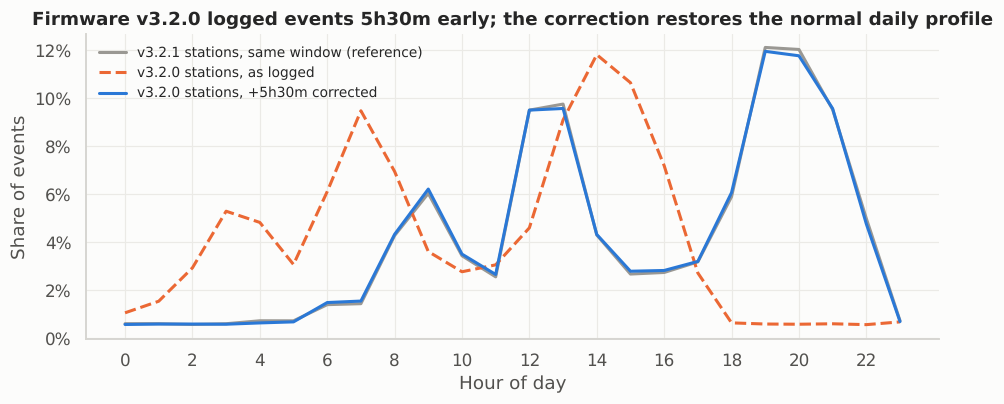

Correlation with reference profile  raw: -0.17   corrected: 1.00


In [9]:
BUG_START, BUG_END = pd.Timestamp('2025-03-10'), pd.Timestamp('2025-04-15')   # window inclusive of 14 Apr
in_window = (swaps.event_ts >= BUG_START) & (swaps.event_ts < BUG_END)
bug = in_window & (swaps.station_firmware == 'v3.2.0')
print(f'Affected events: {bug.sum():,} ({bug.mean():.2%} of events)')

prof = pd.DataFrame({
    'v3.2.0 in window (raw)': swaps.loc[bug, 'event_ts'].dt.hour.value_counts(normalize=True),
    'v3.2.1 in window': swaps.loc[in_window & ~bug, 'event_ts'].dt.hour.value_counts(normalize=True),
}).sort_index()
swaps.loc[bug, 'event_ts'] = swaps.loc[bug, 'event_ts'] + pd.Timedelta(hours=5, minutes=30)
swaps['ts_corrected'] = bug
prof['v3.2.0 in window (corrected)'] = swaps.loc[bug, 'event_ts'].dt.hour.value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(prof.index, prof['v3.2.1 in window'], color=GREY, lw=2, label='v3.2.1 stations, same window (reference)')
ax.plot(prof.index, prof['v3.2.0 in window (raw)'], color=PAL[1], lw=2, ls='--', label='v3.2.0 stations, as logged')
ax.plot(prof.index, prof['v3.2.0 in window (corrected)'], color=PAL[0], lw=2, label='v3.2.0 stations, +5h30m corrected')
ax.yaxis.set_major_formatter(pct); ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hour of day'); ax.set_ylabel('Share of events')
ax.set_title('Firmware v3.2.0 logged events 5h30m early; the correction restores the normal daily profile')
ax.legend(frameon=False, fontsize=9); save(fig, '01_firmware_shift'); plt.show()
print('Correlation with reference profile  raw: %.2f   corrected: %.2f' % (
    prof['v3.2.0 in window (raw)'].corr(prof['v3.2.1 in window']),
    prof['v3.2.0 in window (corrected)'].corr(prof['v3.2.1 in window'])))

The raw v3.2.0 profile peaks around 07:00 and 14:00, while every other station peaks around 12:00-13:00 and 19:00-21:00. After adding 5h30m the two profiles line up almost perfectly, which confirms both the bug and the fix. **All hour-of-day analysis below uses the corrected timestamp.**

### 3.3 Offline-batch near-duplicates
The brief describes offline-sync retries: same rider, station and batteries, a few seconds to a couple of minutes apart. We search for them directly rather than assume.

In [10]:
key_cols = ['rider_id', 'station_id', 'battery_in_id', 'battery_out_id']
k = pd.DataFrame({c: swaps[c].cat.codes for c in key_cols})          # integer codes: same comparison, a fraction of the memory
k['event_ts'] = swaps.event_ts.values
k = k.sort_values(key_cols + ['event_ts'])
same = (k[key_cols].diff() == 0).all(axis=1)
k['gap_s'] = k.event_ts.diff().dt.total_seconds().where(same)
bins = [-1, 60, 180, 600, 3600, 86400, 1e9]
labels = ['<=1 min', '1-3 min', '3-10 min', '10-60 min', '1-24 h', '>1 day']
print('Gap to previous event with identical rider + station + batteries:')
print(pd.cut(k.gap_s.dropna(), bins, labels=labels).value_counts().sort_index())
near_dup = k.gap_s.le(180) & (k.battery_in_id >= 0)
print(f'\nNear-duplicates (identical keys within 3 min, battery inserted): {near_dup.sum():,}')
print('\nShare of events synced offline_batch, by connectivity tier:')
tier = swaps.station_id.map(stations.set_index('station_id').connectivity_tier)
print((swaps.sync_mode == 'offline_batch').groupby(tier.astype(str)).mean().round(3))
swaps = swaps.drop(index=k.index[near_dup])
del k, tier

Gap to previous event with identical rider + station + batteries:
gap_s
<=1 min          0
1-3 min          0
3-10 min         0
10-60 min        5
1-24 h         110
>1 day       10360
Name: count, dtype: int64

Near-duplicates (identical keys within 3 min, battery inserted): 0

Share of events synced offline_batch, by connectivity tier:


station_id
fair    0.451
good    0.000
poor    0.451
Name: sync_mode, dtype: float64


**Finding:** `offline_batch` sync is real and confined to fair and poor connectivity stations (about 45% of their events), but in this export **we find essentially no near-duplicate records**: no pair of events shares rider, station and both batteries within 10 minutes. The de-duplication rule is kept in the pipeline (it drops whatever it finds, here almost nothing), so it is safe if the data is refreshed. Treating every offline_batch row as a duplicate would have wrongly deleted about 15% of real swaps.

### 3.4 City spellings in `riders.home_city`

In [11]:
print(riders.home_city.value_counts().to_string())
CITY_MAP = {'bengaluru': 'Bengaluru', 'bangalore': 'Bengaluru', 'blr': 'Bengaluru',
            'delhi ncr': 'Delhi NCR', 'delhi': 'Delhi NCR', 'new delhi': 'Delhi NCR', 'gurgaon': 'Delhi NCR', 'gurugram': 'Delhi NCR', 'noida': 'Delhi NCR', 'del': 'Delhi NCR',
            'mumbai': 'Mumbai', 'bombay': 'Mumbai', 'mum': 'Mumbai',
            'hyderabad': 'Hyderabad', 'hyd': 'Hyderabad', 'pune': 'Pune', 'pun': 'Pune', 'jaipur': 'Jaipur', 'jai': 'Jaipur'}
riders['home_city_raw'] = riders.home_city
riders['home_city'] = riders.home_city.str.strip().str.lower().map(CITY_MAP)
assert riders.home_city.notna().all(), riders.loc[riders.home_city.isna(), 'home_city_raw'].unique()
# Cross-check with the zone prefix, which is clean
zone_city = riders.home_zone.str[:3].map({'BLR': 'Bengaluru', 'DEL': 'Delhi NCR', 'MUM': 'Mumbai', 'HYD': 'Hyderabad', 'PUN': 'Pune', 'JAI': 'Jaipur'})
print(f'\n21 raw spellings -> {riders.home_city.nunique()} cities; agreement with home_zone prefix: {(zone_city == riders.home_city).mean():.1%}')

home_city
Bengaluru     4175
Delhi NCR     3783
Hyderabad     3396
Pune          2843
Mumbai        2772
Jaipur        2446
Bombay          53
BLR             53
bengaluru       50
MUM             49
pune            43
PUN             43
New Delhi       42
JAI             41
Gurgaon         36
Bangalore       32
HYD             31
Hyd             31
jaipur          29
hyderabad       27
Delhi           25

21 raw spellings -> 6 cities; agreement with home_zone prefix: 100.0%


### 3.5 Distance and charge-reading outliers

In [12]:
km = swaps.km_since_last_swap
print(f'km_since_last_swap < 0      : {(km < 0).sum():,} ({(km < 0).mean():.2%})')
print(f'km_since_last_swap > 200 km : {(km > 200).sum():,} ({(km > 200).mean():.2%})')
print('km percentiles (valid):', km[(km >= 0) & (km <= 200)].quantile([.01, .5, .99]).round(1).to_dict())
for c in ['soc_in_pct', 'soc_out_pct', 'soh_in_pct', 'soh_out_pct']:
    print(f'{c} > 100: {(swaps[c] > 100).sum():,}')
# Odometer resets -> NaN (not zero); calibration drift -> cap at 100
swaps['km_clean'] = km.where((km >= 0) & (km <= 200))
for c in ['soc_in_pct', 'soc_out_pct', 'soh_in_pct', 'soh_out_pct']:
    swaps[c] = swaps[c].clip(upper=100)

km_since_last_swap < 0      : 7,687 (0.20%)
km_since_last_swap > 200 km : 7,600 (0.20%)
km percentiles (valid): {0.01: 33.1, 0.5: 59.9, 0.99: 105.5}
soc_in_pct > 100: 0
soc_out_pct > 100: 3,634
soh_in_pct > 100: 3,298
soh_out_pct > 100: 2,752


Negative or >200 km readings (about 0.4%) are set to missing rather than zero, because they are odometer resets, not real distances; a 2.1 kWh pack cannot plausibly cover 200+ km. SOC/SOH readings slightly above 100% are sensor drift and are capped at 100.

### 3.6 Missing telemetry in hourly status

In [13]:
hourly = hourly.merge(stations[['station_id', 'connectivity_tier']], on='station_id', how='left')
print(pd.crosstab(hourly.connectivity_tier, hourly.telemetry_status, normalize='index').round(4))
print('\nBlank share of numeric fields by telemetry_status:')
print(hourly.groupby('telemetry_status', observed=True)[['charged_2w_min', 'avg_charge_minutes', 'grid_kwh']].apply(lambda d: d.isna().mean()).round(3))

telemetry_status   missing      ok  partial
connectivity_tier                          
fair                  0.00  0.9605   0.0395
good                  0.00  0.9899   0.0101
poor                  0.04  0.8910   0.0690

Blank share of numeric fields by telemetry_status:
                  charged_2w_min  avg_charge_minutes  grid_kwh
telemetry_status                                              
missing                      1.0                 1.0       1.0
ok                           0.0                 0.0       0.0
partial                      0.0                 0.0       0.0


Blank telemetry is concentrated at poor-connectivity stations (about 11% of hours vs 1% at good stations). Blanks are **left as missing** and every hourly metric is a mean over hours that reported, never a sum that treats blanks as zero. `charged_3w_min` is also structurally blank at stations with no 3W slots.

### 3.7 Support tickets: dates, CSAT and category

In [14]:
out_of_range = ~tickets.created_ts.between('2024-01-01', '2025-07-01')
print(f'Tickets dated outside Jan 2024 to Jun 2025: {out_of_range.sum()} -> excluded')
tickets = tickets[~out_of_range].copy()
tickets['res_bucket'] = pd.cut(tickets.resolution_hours, [0, 6, 12, 24, 48, 1000], labels=['<6h', '6-12h', '12-24h', '24-48h', '>48h'])
csat_resp = tickets.groupby('res_bucket', observed=True).agg(tickets=('ticket_id', 'size'), csat_recorded=('csat_score', lambda x: x.notna().mean()), mean_csat=('csat_score', 'mean'))
csat_resp.round(3)

Tickets dated outside Jan 2024 to Jun 2025: 85 -> excluded


,tickets,csat_recorded,mean_csat
res_bucket,,,
<6h,4320,0.436,3.572
6-12h,12226,0.441,3.525
12-24h,14464,0.434,3.570
24-48h,5649,0.215,3.599
>48h,691,0.221,3.641


CSAT is recorded for about 44% of tickets resolved within 24h but only about 22% of slower ones, and none of the unresolved ones. A naive average over-represents fast, easy tickets. We correct with **inverse-probability weighting** by resolution bucket (each recorded score is weighted by 1 / response rate of its bucket) in the ticket analysis below. The agent-assigned `category` is re-checked against the comment text in deep dive D4.

### 3.8 Build the analysis tables
Join station, rider, partner and battery attributes onto swaps, and compute the **unit economics of each completed swap**.

**Contribution margin per completed swap (CM)** = revenue − energy − battery wear − site cost, where
- *energy* = `energy_to_recharge_kwh` × station `grid_tariff_inr_kwh`
- *battery wear* = pack purchase cost × (SOH points consumed per swap ÷ usable SOH budget). The usable budget is taken from the data itself: packs retired for `end_of_life` were retired at about 60% SOH, so a pack has roughly 99 − 60 ≈ 39 SOH points of life. SOH consumed per swap is **measured** per supplier and pack type from the swap telemetry (SOH at commissioning minus last observed SOH, divided by swaps served)
- *site cost* = station monthly rent + maintenance ÷ completed swaps at that station in that month

The wear assumption changes the *level* of CM, but not its *trend* or the ranking of segments, which is what the analysis relies on. We report CM before wear (CM1) and after wear (CM2) separately.

In [15]:
st_cols = ['station_id', 'city', 'zone', 'location_type', 'host_type', 'commissioned_date', 'expansion_wave', 'charger_generation',
           'slots_2w', 'slots_3w', 'inventory_target_2w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh',
           'connectivity_tier', 'competitor_within_1_5km_since']
st_idx = stations.set_index('station_id')
for c in st_cols[1:]:
    v = swaps.station_id.map(st_idx[c])
    swaps[c] = v.astype('category') if v.dtype == object or str(v.dtype) in ('str', 'string') else v
rd_idx = riders.set_index('rider_id')
for c in ['partner_id', 'vehicle_class', 'plan_type', 'signup_channel', 'home_city']:
    swaps[c] = swaps.rider_id.map(rd_idx[c]).astype('category')
swaps['signup_date'] = swaps.rider_id.map(rd_idx.signup_date)
swaps['segment'] = pd.Categorical(np.where(swaps.partner_id.isna(), 'Independent', 'Fleet partner'))
swaps['month'] = swaps.event_ts.dt.to_period('M')
swaps['hour'] = swaps.event_ts.dt.hour
swaps['mon'] = swaps.event_ts.dt.month
swaps['season'] = swaps.mon.map({**{m: 'Summer (Apr-Jun)' for m in (4, 5, 6)}, **{m: 'Monsoon (Jul-Sep)' for m in (7, 8, 9)}, **{m: 'Winter/other' for m in (1, 2, 3, 10, 11, 12)}}).astype('category')
swaps['completed'] = swaps.event_type == 'swap_completed'
swaps['failed'] = ~swaps.completed
swaps['no_battery'] = swaps.event_type == 'failed_no_charged_battery'
swaps['abandoned'] = swaps.event_type == 'abandoned_queue'
swaps['sys_error'] = swaps.event_type == 'failed_system_error'

bat = batteries.set_index('battery_id')
swaps['sup_out'] = swaps.battery_out_id.map(bat.supplier).astype('category')
swaps['sup_in'] = swaps.battery_in_id.map(bat.supplier).astype('category')
swaps['lot_in'] = swaps.battery_in_id.map(bat.manufacturing_lot).astype('category')

comp = swaps[swaps.completed].copy()
import gc; gc.collect()

# --- measured SOH consumed per swap, per supplier x pack type ---
last_obs = comp.sort_values('event_ts').groupby('battery_out_id').agg(last_soh=('soh_out_pct', 'last'), n_swaps=('event_id', 'size'))
batteries = batteries.merge(last_obs, left_on='battery_id', right_index=True, how='left')
batteries['soh_per_swap'] = (batteries.initial_soh_pct - batteries.last_soh) / batteries.n_swaps
soh_rate = batteries.groupby(['supplier', 'pack_type']).soh_per_swap.median()
print('Median SOH points consumed per swap:'); print(soh_rate.round(4))
eol_soh = batteries.loc[batteries.retirement_reason == 'end_of_life', 'current_soh_pct'].mean()
SOH_BUDGET = batteries.initial_soh_pct.mean() - eol_soh
print(f'\nSOH at end-of-life retirement: {eol_soh:.1f}%  ->  usable SOH budget per pack: {SOH_BUDGET:.1f} points')
batteries['wear_inr_per_swap'] = batteries.purchase_cost_inr * batteries.set_index(['supplier', 'pack_type']).index.map(soh_rate) / SOH_BUDGET
bat = batteries.set_index('battery_id')

comp['energy_cost'] = comp.energy_to_recharge_kwh * comp.grid_tariff_inr_kwh
comp['wear_cost'] = comp.battery_out_id.map(bat.wear_inr_per_swap)
sm = comp.groupby(['station_id', 'month'], observed=True).size().rename('station_month_swaps')
comp = comp.join(sm, on=['station_id', 'month'])
comp['site_cost'] = (comp.monthly_rent_inr + comp.monthly_maintenance_inr) / comp.station_month_swaps
comp['cm1'] = comp.amount_charged_inr - comp.energy_cost - comp.site_cost        # before battery wear
comp['cm2'] = comp.cm1 - comp.wear_cost                                         # after battery wear
# Counterfactual used in Q1: what wear would have been if Kyron packs had degraded like Cellora packs of the same type
cf_rate = batteries.pack_type.map(soh_rate.xs('Cellora', level='supplier'))
batteries['wear_cf_inr_per_swap'] = batteries.purchase_cost_inr * cf_rate / SOH_BUDGET
comp['cm2_cf'] = comp.cm1 - comp.battery_out_id.map(batteries.set_index('battery_id').wear_cf_inr_per_swap)
print(f'\nCompleted swaps analysed: {len(comp):,}')
comp[['amount_charged_inr', 'energy_cost', 'site_cost', 'wear_cost', 'cm1', 'cm2']].describe().round(2)

Median SOH points consumed per swap:
supplier  pack_type
Amptek    2W_2.1kWh    0.0299
          3W_4.8kWh    0.0337
Cellora   2W_2.1kWh    0.0298
          3W_4.8kWh    0.0335
Kyron     2W_2.1kWh    0.0962
          3W_4.8kWh    0.0350
Name: soh_per_swap, dtype: float64

SOH at end-of-life retirement: 60.8%  ->  usable SOH budget per pack: 38.4 points



Completed swaps analysed: 3,586,675


,amount_charged_inr,energy_cost,site_cost,wear_cost,cm1,cm2
count,3586675.00,3586675.00,3586675.00,3586675.00,3586675.00,3586675.00
mean,63.90,19.49,13.41,37.12,31.00,-6.12
std,14.51,7.79,8.08,21.36,13.41,22.34
min,36.80,6.92,3.53,21.86,-898.50,-944.06
25%,55.25,15.67,8.72,24.51,22.69,-13.82
50%,59.80,17.40,12.15,25.31,30.63,-0.94
75%,65.00,19.32,16.36,56.88,38.43,8.32
max,135.00,61.18,934.57,89.46,92.47,45.96


## 4. Core question analysis

### Q1. Network performance over time
How have completed swaps, revenue, failure rates and contribution margin per swap trended? Do they tell the same story?

In [16]:
m_all = swaps.groupby('month').agg(attempts=('event_id', 'size'), failed_attempts=('failed', 'sum'), failure_rate=('failed', 'mean'), no_battery_rate=('no_battery', 'mean'),
                                   abandon_rate=('abandoned', 'mean'), median_queue_s=('queue_wait_sec', 'median'), stations=('station_id', 'nunique'))
m_comp = comp.groupby('month').agg(completed=('event_id', 'size'), revenue_inr=('amount_charged_inr', 'sum'), revenue_per_swap=('amount_charged_inr', 'mean'),
                                   energy=('energy_cost', 'mean'), site=('site_cost', 'mean'), wear=('wear_cost', 'mean'), cm1=('cm1', 'mean'), cm2=('cm2', 'mean'), cm2_cf=('cm2_cf', 'mean'),
                                   kyron_share=('sup_out', lambda x: (x == 'Kyron').mean()))
monthly = m_all.join(m_comp)
monthly['tickets'] = tickets.groupby(tickets.created_ts.dt.to_period('M')).size()
monthly['tickets_per_10k_attempts'] = monthly.tickets / monthly.attempts * 1e4
monthly.round(3)

,attempts,failed_attempts,failure_rate,no_battery_rate,abandon_rate,median_queue_s,stations,completed,revenue_inr,revenue_per_swap,energy,site,wear,cm1,cm2,cm2_cf,kyron_share,tickets,tickets_per_10k_attempts
month,,,,,,,,,,,,,,,,,,,
2024-01,108278,4770,0.044,0.024,0.013,206.0,90,103508,6198803.40,59.887,22.006,20.376,28.799,17.505,-11.294,-11.206,0.029,654,60.400
2024-02,109271,4834,0.044,0.024,0.013,207.0,90,104437,6256296.00,59.905,21.899,20.195,28.825,17.811,-11.015,-10.926,0.029,696,63.695
2024-03,121487,5339,0.044,0.024,0.013,206.0,90,116148,6952642.00,59.860,21.714,18.159,28.764,19.987,-8.776,-8.690,0.028,766,63.052
2024-04,128991,8874,0.069,0.041,0.020,206.0,90,120117,7204036.20,59.975,21.595,17.559,28.838,20.821,-8.016,-7.928,0.029,1135,87.991
2024-05,143189,17735,0.124,0.078,0.038,202.0,90,125454,7513212.80,59.888,21.331,16.812,28.751,21.745,-7.006,-6.919,0.029,2022,141.212
2024-06,145880,15000,0.103,0.064,0.031,203.0,90,130880,7827373.00,59.806,21.030,16.115,28.656,22.661,-5.996,-5.911,0.028,1785,122.361
2024-07,155343,6732,0.043,0.024,0.013,207.0,90,148611,9666799.25,65.048,20.857,14.192,28.713,29.999,1.286,1.372,0.028,1054,67.850
2024-08,168900,7212,0.043,0.023,0.013,207.0,100,161688,10509533.60,64.999,20.647,14.666,28.693,29.685,0.992,1.077,0.028,1195,70.752
2024-09,192479,8428,0.044,0.024,0.012,206.0,108,184051,11903273.70,64.674,20.460,13.848,37.434,30.366,-7.068,2.007,0.189,1775,92.218


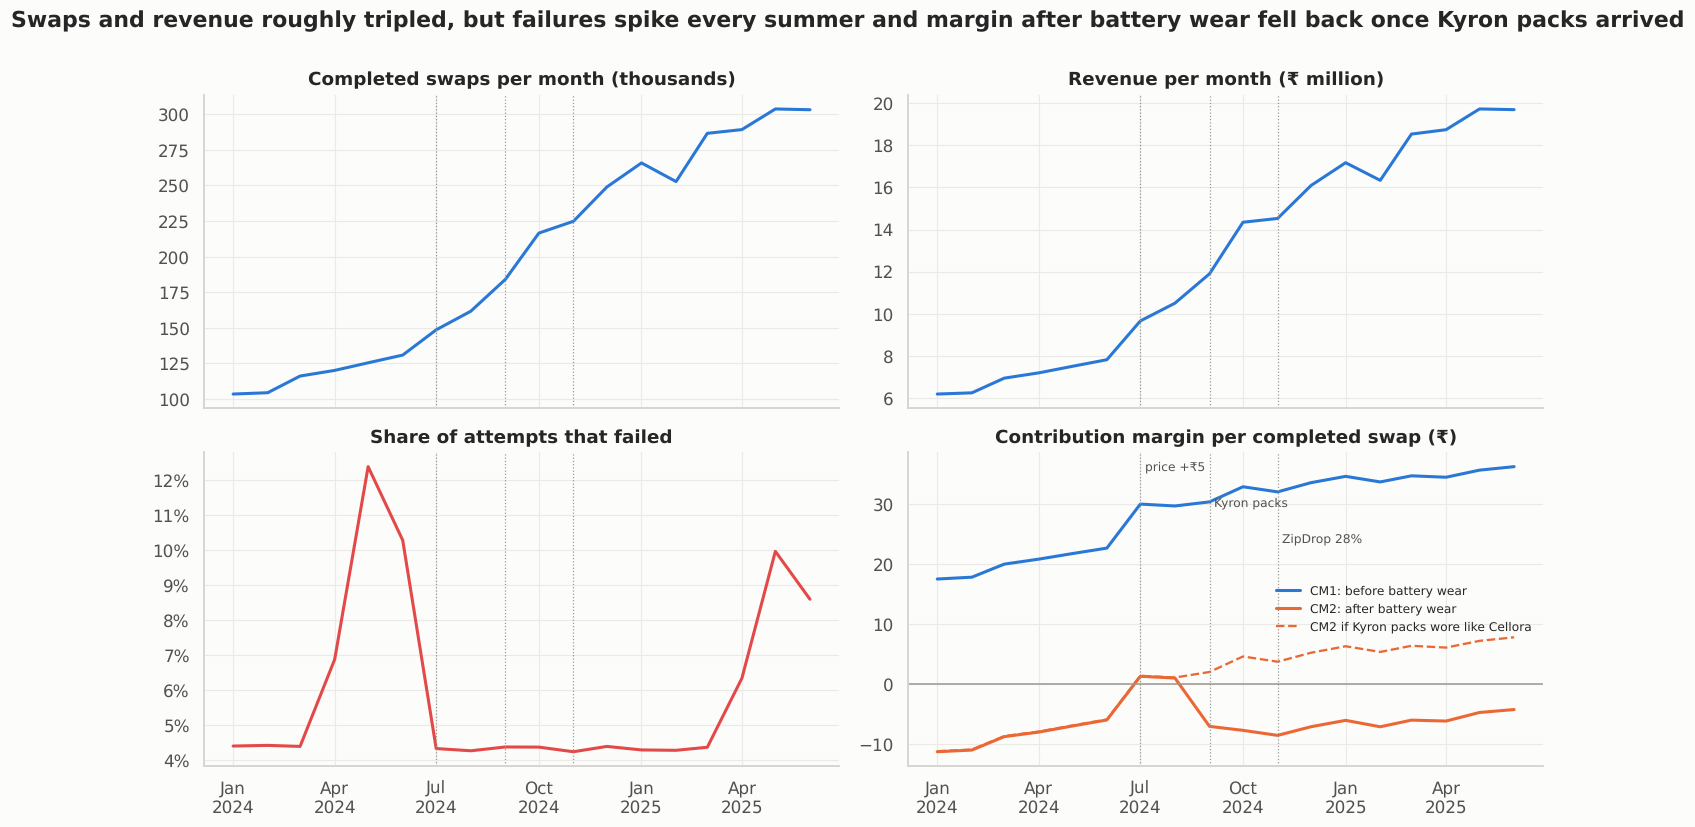

In [17]:
x = monthly.index.to_timestamp()
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
ax = axes[0, 0]; ax.plot(x, monthly.completed / 1e3, color=PAL[0]); ax.set_title('Completed swaps per month (thousands)')
ax = axes[0, 1]; ax.plot(x, monthly.revenue_inr / 1e6, color=PAL[0]); ax.set_title('Revenue per month (₹ million)')
ax = axes[1, 0]; ax.plot(x, monthly.failure_rate, color=PAL[7]); ax.yaxis.set_major_formatter(pct); ax.set_title('Share of attempts that failed')
ax = axes[1, 1]
ax.plot(x, monthly.cm1, color=PAL[0], label='CM1: before battery wear')
ax.plot(x, monthly.cm2, color=PAL[1], label='CM2: after battery wear')
ax.plot(x, monthly.cm2_cf, color=PAL[1], ls='--', lw=1.5, label='CM2 if Kyron packs wore like Cellora')
ax.axhline(0, color=GREY, lw=1); ax.set_title('Contribution margin per completed swap (₹)')
for a in axes.flat:
    fmt_dates(a)
    for d in ['2024-07-01', '2024-09-01', '2024-11-01']:
        a.axvline(pd.Timestamp(d), color=GREY, lw=0.8, ls=':')
ymax = axes[1, 1].get_ylim()[1]
for d, lab, dy in [('2024-07-01', 'price +₹5', 0), ('2024-09-01', 'Kyron packs', 6), ('2024-11-01', 'ZipDrop 28%', 12)]:
    axes[1, 1].text(pd.Timestamp(d) + pd.Timedelta(days=4), ymax - 3 - dy, lab, fontsize=8, color='#52514e')
axes[1, 1].legend(frameon=False, fontsize=8, loc='center right')
fig.suptitle('Swaps and revenue roughly tripled, but failures spike every summer and margin after battery wear fell back once Kyron packs arrived', fontweight='bold', y=1.0)
fig.tight_layout(); save(fig, '02_kpi_trends'); plt.show()

In [18]:
def period_summary(df, start, end):
    d = df.loc[start:end]
    return pd.Series({'completed_per_month': d.completed.mean(), 'revenue_per_month_inr': d.revenue_inr.mean(), 'failed_attempts_per_month': d.failed_attempts.mean(),
                      'failure_rate': d.failed_attempts.sum() / d.attempts.sum(), 'tickets_per_10k_attempts': d.tickets.sum() / d.attempts.sum() * 1e4,
                      'revenue_per_swap': d.revenue_per_swap.mean(), 'cm1': d.cm1.mean(), 'cm2': d.cm2.mean()})
comp_tbl = pd.DataFrame({'H1 2024': period_summary(monthly, '2024-01', '2024-06'), 'H2 2024': period_summary(monthly, '2024-07', '2024-12'),
                         'H1 2025': period_summary(monthly, '2025-01', '2025-06')})
comp_tbl['H1 2025 vs H1 2024'] = comp_tbl['H1 2025'] / comp_tbl['H1 2024'] - 1
comp_tbl.round(3)

,H1 2024,H2 2024,H1 2025,H1 2025 vs H1 2024
completed_per_month,116757.333,1.974520e+05,2.835698e+05,1.429
revenue_per_month_inr,6992060.567,1.284143e+07,1.836573e+07,1.627
failed_attempts_per_month,9425.333,8.947333e+03,1.967850e+04,1.088
failure_rate,0.075,4.300000e-02,6.500000e-02,-0.131
tickets_per_10k_attempts,93.225,9.166700e+01,1.372360e+02,0.472
revenue_per_swap,59.887,6.503800e+01,6.475800e+01,0.081
cm1,20.088,3.142400e+01,3.490100e+01,0.737
cm2,-8.684,-4.701000e+00,-5.734000e+00,-0.340


CM2 per swap H1 2024: ₹-8.7   H1 2025: ₹-5.7   change: ₹3.0
Kyron share of issued packs H1 2024: 2.9%   H1 2025: 24.6%


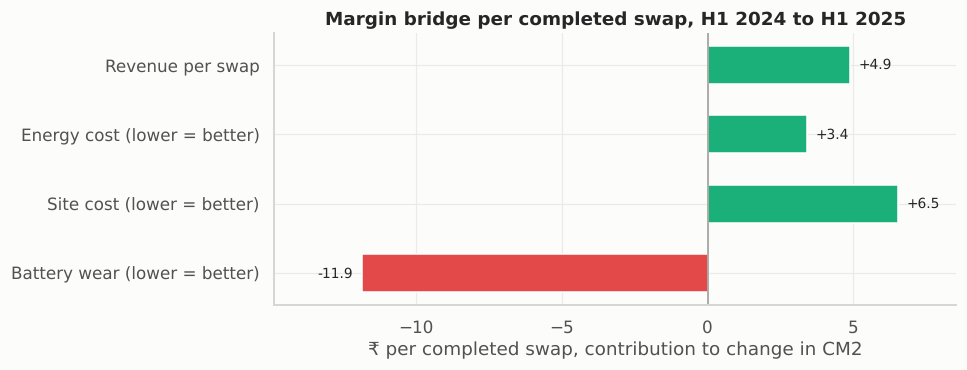

Revenue per swap                  4.87
Energy cost (lower = better)      3.41
Site cost (lower = better)        6.53
Battery wear (lower = better)   -11.86
dtype: float64

In [19]:
# Bridge: what moved CM2 per swap between H1 2024 and H1 2025?
a, b = monthly.loc['2024-01':'2024-06'].mean(numeric_only=True), monthly.loc['2025-01':'2025-06'].mean(numeric_only=True)
bridge = pd.Series({'Revenue per swap': b.revenue_per_swap - a.revenue_per_swap, 'Energy cost (lower = better)': -(b.energy - a.energy),
                    'Site cost (lower = better)': -(b.site - a.site), 'Battery wear (lower = better)': -(b.wear - a.wear)})
print(f'CM2 per swap H1 2024: ₹{a.cm2:.1f}   H1 2025: ₹{b.cm2:.1f}   change: ₹{b.cm2 - a.cm2:.1f}')
print(f'Kyron share of issued packs H1 2024: {a.kyron_share:.1%}   H1 2025: {b.kyron_share:.1%}')
fig, ax = plt.subplots(figsize=(8, 3.2))
cols = [PAL[2] if v > 0 else PAL[7] for v in bridge.values]
ax.barh(bridge.index, bridge.values, color=cols, height=0.55); ax.axvline(0, color=GREY, lw=1)
for i, v in enumerate(bridge.values):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f'{v:+.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_xlabel('₹ per completed swap, contribution to change in CM2'); ax.invert_yaxis(); ax.set_xlim(bridge.min() - 3, bridge.max() + 2)
ax.set_title('Margin bridge per completed swap, H1 2024 to H1 2025')
save(fig, '03_margin_bridge'); plt.show()
bridge.round(2)

**Q1 answer: the metrics do not tell the same story.**
- **Volume and revenue grew strongly.** Completed swaps rose from about 104k in Jan 2024 to about 303k a month in Jun 2025 (~2.9x) and monthly revenue from ₹6.2M to ₹19.7M (~3.2x), as the network grew from 90 to 150 stations.
- **Failures are seasonal, and growing in absolute terms.** The failure *rate* sits near 4.3% in cool months and jumps to 12.4% (May 2024) and 10.0% (May 2025). Because volume doubled, failed attempts per month in H1 2025 (~19.7k) were 2.1x H1 2024.
- **Complaints grew faster than the business.** Support tickets per 10,000 attempts rose from about 60 in Jan 2024 to about 164 in Jun 2025. As D4 shows, most of that growth is battery-range complaints.
- **New-rider retention dips with the failure spikes.** The share of new riders not returning in their second month peaked at 21% for May 2024 starters and climbed back to 18% for Apr 2025 starters (Q6).
- **Margin per swap moved in a different direction from revenue.** Before battery wear (CM1), margin per swap doubled from ₹17.5 to ₹36 thanks to the July 2024 price rise and falling energy and site cost per swap. After battery wear (CM2) it briefly turned positive in Jul-Aug 2024 and then **fell back by about ₹8-9 per swap from September 2024**, exactly when Kyron packs went from 3% to 25% of issued packs. The bridge from H1 2024 to H1 2025 shows +₹4.9 from price, +₹3.4 energy and +₹6.5 site efficiency, almost all of it (−₹11.9) consumed by higher battery wear. Had Kyron packs worn like Cellora packs (dashed line), CM2 would be about ₹8 per swap today instead of about −₹4.
- *Caveat:* the CM2 **level** depends on the wear assumption (full pack cost spread over ~39 SOH points of life); the **trend** and the Kyron step-change do not.

### Q2. Service failures and customer experience
How do queue wait, failed attempts and abandoned swaps relate to station, hour, season and vehicle class? Is the damage spread evenly?

In [20]:
def fail_profile(by):
    return swaps.groupby(by, observed=True).agg(attempts=('event_id', 'size'), failure_rate=('failed', 'mean'), no_battery=('no_battery', 'mean'),
                                                abandoned=('abandoned', 'mean'), sys_error=('sys_error', 'mean'),
                                                queue_mean_s=('queue_wait_sec', 'mean'), queue_p90_s=('queue_wait_sec', lambda x: x.quantile(.9)))
print('Failure mix (share of all attempts):'); print(swaps.event_type.value_counts(normalize=True).round(4))
fail_profile('vehicle_class').round(4)

Failure mix (share of all attempts):
event_type
swap_completed               0.9402
failed_no_charged_battery    0.0348
abandoned_queue              0.0177
cancelled_by_rider           0.0043
failed_system_error          0.0030
Name: proportion, dtype: float64


,attempts,failure_rate,no_battery,abandoned,sys_error,queue_mean_s,queue_p90_s
vehicle_class,,,,,,,
2W,3399568,0.0545,0.0312,0.0160,0.0030,242.9734,436.0
3W,415414,0.1039,0.0642,0.0323,0.0031,242.7519,449.0


In [21]:
fail_profile('season').round(4)

,attempts,failure_rate,no_battery,abandoned,sys_error,queue_mean_s,queue_p90_s
season,,,,,,,
Monsoon (Jul-Sep),516722,0.0433,0.0235,0.0126,0.0029,243.1197,433.0
Summer (Apr-Jun),1395999,0.0884,0.0545,0.0266,0.0030,242.6849,445.0
Winter/other,1902261,0.0434,0.0235,0.0126,0.0030,243.0970,434.0


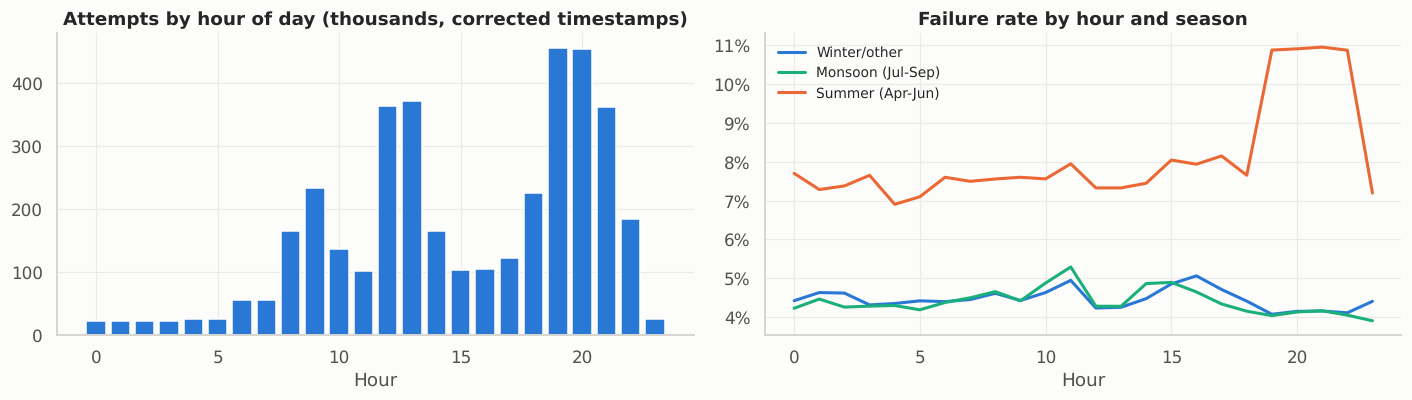

In [22]:
hr = swaps.pivot_table(index='hour', columns='season', values='failed', aggfunc='mean')
vol = swaps.groupby('hour').size()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]; ax.bar(vol.index, vol.values / 1e3, color=PAL[0], width=0.8); ax.set_title('Attempts by hour of day (thousands, corrected timestamps)'); ax.set_xlabel('Hour')
ax = axes[1]
for i, c in enumerate(['Winter/other', 'Monsoon (Jul-Sep)', 'Summer (Apr-Jun)']):
    ax.plot(hr.index, hr[c], label=c, color=[PAL[0], PAL[2], PAL[1]][i])
ax.yaxis.set_major_formatter(pct); ax.set_title('Failure rate by hour and season'); ax.set_xlabel('Hour'); ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); save(fig, '04_hour_season'); plt.show()

In [23]:
# Queue wait: does it vary by anything?
qw = swaps[swaps.completed]
print('Completed-swap queue wait (s) by season / class / generation / hour-band:')
print(qw.groupby('season').queue_wait_sec.median().to_dict())
print(qw.groupby('vehicle_class', observed=True).queue_wait_sec.median().to_dict())
print(qw.groupby('charger_generation').queue_wait_sec.median().to_dict())
print(qw.groupby(pd.cut(qw.hour, [-1, 6, 11, 15, 18, 23])).queue_wait_sec.median().to_dict())
print('Abandoned attempts waited (median s):', swaps.loc[swaps.abandoned, 'queue_wait_sec'].median())

Completed-swap queue wait (s) by season / class / generation / hour-band:
{'Monsoon (Jul-Sep)': 209.0, 'Summer (Apr-Jun)': 210.0, 'Winter/other': 209.0}


{'2W': 210.0, '3W': 209.0}
{'Gen1': 209.0, 'Gen2': 209.0, 'Gen3': 210.0}


{Interval(-1, 6, closed='right'): 210.0, Interval(6, 11, closed='right'): 210.0, Interval(11, 15, closed='right'): 209.0, Interval(15, 18, closed='right'): 210.0, Interval(18, 23, closed='right'): 209.0}
Abandoned attempts waited (median s): 648.0


In [24]:
# Concentration: how unevenly are failures spread across stations?
st_f = swaps.groupby('station_id', observed=True).agg(attempts=('event_id', 'size'), fails=('failed', 'sum'), no_bat=('no_battery', 'sum')).join(
    stations.set_index('station_id')[['city', 'charger_generation', 'location_type', 'expansion_wave']])
st_f['failure_rate'] = st_f.fails / st_f.attempts
st_f = st_f.sort_values('fails', ascending=False)
st_f['cum_fail_share'] = st_f.fails.cumsum() / st_f.fails.sum()
st_f['cum_attempt_share'] = st_f.attempts.cumsum() / st_f.attempts.sum()
n20 = int(round(len(st_f) * 0.2))
print(f'Top 20% of stations ({n20}) account for {st_f.cum_fail_share.iloc[n20-1]:.1%} of failed attempts but {st_f.cum_attempt_share.iloc[n20-1]:.1%} of attempts')
print('Generation mix of the top-20% stations:', st_f.head(n20).charger_generation.value_counts().to_dict())
print('City mix of the top-20% stations:', st_f.head(n20).city.value_counts().to_dict())
st_f.head(15)[['city', 'charger_generation', 'location_type', 'attempts', 'failure_rate']].round(3)

Top 20% of stations (30) account for 41.8% of failed attempts but 31.0% of attempts
Generation mix of the top-20% stations: {'Gen1': 30}
City mix of the top-20% stations: {'Delhi NCR': 11, 'Jaipur': 9, 'Hyderabad': 9, 'Bengaluru': 1}


,city,charger_generation,location_type,attempts,failure_rate
station_id,,,,,
STN-DEL-043,Delhi NCR,Gen1,commercial_hub,49597,0.086
STN-JAI-138,Jaipur,Gen1,market,48945,0.087
STN-HYD-072,Hyderabad,Gen1,commercial_hub,51765,0.081
STN-DEL-050,Delhi NCR,Gen1,commercial_hub,47060,0.086
STN-JAI-141,Jaipur,Gen1,commercial_hub,45594,0.087
STN-JAI-137,Jaipur,Gen1,commercial_hub,44371,0.087
STN-HYD-070,Hyderabad,Gen1,market,49688,0.076
STN-JAI-140,Jaipur,Gen1,commercial_hub,44115,0.085
STN-JAI-134,Jaipur,Gen1,commercial_hub,42925,0.084


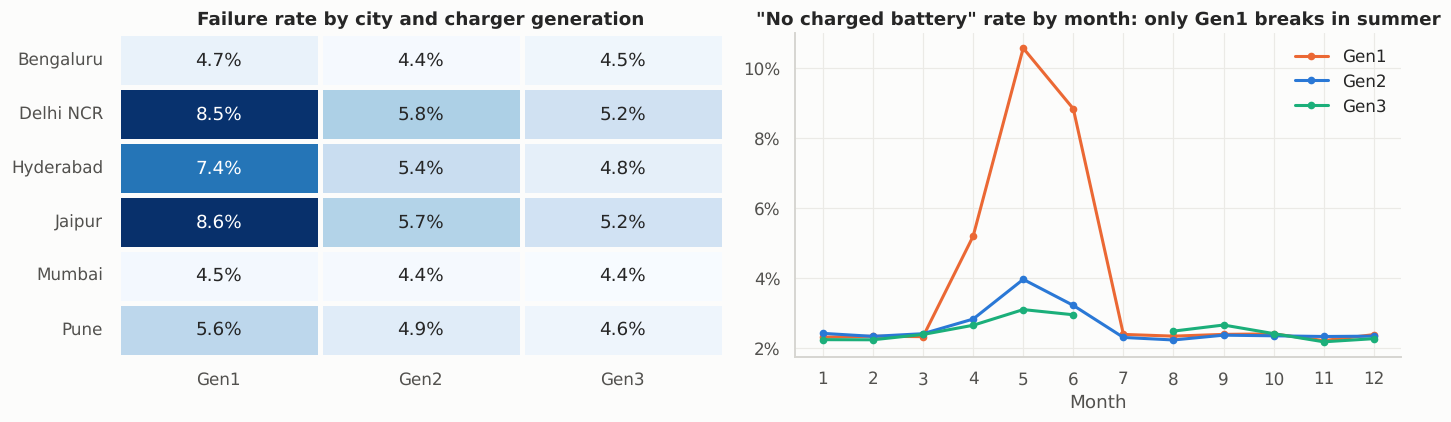

In [25]:
cg = swaps.pivot_table(index='city', columns='charger_generation', values='failed', aggfunc='mean')
sg = swaps.pivot_table(index=swaps.mon, columns='charger_generation', values='no_battery', aggfunc='mean')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(cg, annot=True, fmt='.1%', cmap='Blues', cbar=False, ax=axes[0], linewidths=2, linecolor='#fcfcfb')
axes[0].set_title('Failure rate by city and charger generation'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
for g in ['Gen1', 'Gen2', 'Gen3']:
    axes[1].plot(sg.index, sg[g], marker='o', ms=4, label=g, color=GEN_COL[g])
axes[1].yaxis.set_major_formatter(pct); axes[1].set_xticks(range(1, 13)); axes[1].set_xlabel('Month')
axes[1].set_title('"No charged battery" rate by month: only Gen1 breaks in summer'); axes[1].legend(frameon=False)
fig.tight_layout(); save(fig, '05_city_gen_month'); plt.show()

**Q2 answer: service failures are highly concentrated, not spread evenly.**
- **"No charged battery" dominates** (3.5% of all attempts, about 60% of failures), followed by queue abandonment (1.8%). System errors (0.3%) and rider cancellations (0.4%) are small and flat.
- **Season is the biggest lever**: failure rate is 8.8% in Apr-Jun vs 4.3% the rest of the year. Monsoon has no effect.
- **3W riders fail about twice as often as 2W riders** (10.4% vs 5.5%): stations hold only 0-6 3W slots, so a few slow charges empty the 3W rack.
- **Hour of day**: in summer, failures jump to about 11% in the 19:00-22:00 evening peak, the busiest hours of the day.
- **Queue wait is flat**: the median completed-swap wait is about 3.5 minutes (209 s) regardless of season, class, hour or charger. Riders who abandon have waited a median of 11 minutes. So the real failure is a **stock-out of charged packs**, not a slow queue.
- **Concentration**: the worst 20% of stations (30 stations, **all Gen1**: 11 in Delhi NCR, 9 Jaipur, 9 Hyderabad, 1 Bengaluru) generate 42% of failed attempts while handling 31% of attempts. Only Gen1 shows the summer spike in "no charged battery".

### Q3. Station and geographic patterns
Charger generation, location type, commissioning wave and city: how do they relate to service, battery turnaround (charge time) and complaints?

In [26]:
h = hourly.merge(stations[['station_id', 'city', 'charger_generation', 'location_type', 'expansion_wave', 'slots_3w']], on='station_id', how='left')
h['stockout_2w'] = (h.charged_2w_min == 0).astype(float).where(h.charged_2w_min.notna())
h['stockout_3w'] = (h.charged_3w_min == 0).astype(float).where(h.charged_3w_min.notna())
h['mon'] = h.hour_start.dt.month
h['cab_band'] = pd.cut(h.cabinet_temp_c, [0, 25, 30, 35, 40, 45, 50, 70])

tick_st = tickets.dropna(subset=['station_id']).groupby('station_id').size().rename('tickets')
def station_profile(col):
    a = swaps.groupby(col, observed=True).agg(attempts=('event_id', 'size'), failure_rate=('failed', 'mean'))
    b = h.groupby(col, observed=True).agg(stations=('station_id', 'nunique'), charge_min=('avg_charge_minutes', 'mean'), stockout_2w_hours=('stockout_2w', 'mean'),
                                          stockout_3w_hours=('stockout_3w', 'mean'), cabinet_temp=('cabinet_temp_c', 'mean'))
    # Ticket volume per attempt more than doubled over time, so compare complaint rates within one period (H1 2025, when all waves were open)
    tw = tickets[tickets.created_ts >= '2025-01-01'].merge(stations[['station_id', col]], on='station_id').groupby(col).size()
    aw = swaps[swaps.event_ts >= '2025-01-01'].groupby(col, observed=True).size()
    out = b.join(a)
    out['tickets_per_10k_attempts_H1_2025'] = tw / aw * 1e4
    return out
station_profile('charger_generation').round(3)

,stations,charge_min,stockout_2w_hours,stockout_3w_hours,cabinet_temp,attempts,failure_rate,tickets_per_10k_attempts_H1_2025
charger_generation,,,,,,,,
Gen1,51,91.805,0.023,0.033,24.850,1822034,0.072,150.475
Gen2,62,64.230,0.004,0.000,24.636,1620707,0.048,113.214
Gen3,37,42.142,0.003,0.000,28.274,372241,0.048,123.996


In [27]:
station_profile('location_type').round(3)

,stations,charge_min,stockout_2w_hours,stockout_3w_hours,cabinet_temp,attempts,failure_rate,tickets_per_10k_attempts_H1_2025
location_type,,,,,,,,
commercial_hub,44,79.414,0.015,0.019,24.987,1535743,0.062,132.838
highway_fuel_pump,21,60.080,0.004,0.000,25.036,329834,0.051,131.262
market,47,76.944,0.013,0.023,25.215,1246931,0.062,132.331
residential,21,67.270,0.010,0.003,24.837,382274,0.054,122.893
tech_park,7,76.813,0.018,0.012,24.376,147533,0.052,115.017
transit_hub,10,74.400,0.015,0.018,25.517,172667,0.060,129.089


In [28]:
station_profile('city').round(3)

,stations,charge_min,stockout_2w_hours,stockout_3w_hours,cabinet_temp,attempts,failure_rate,tickets_per_10k_attempts_H1_2025
city,,,,,,,,
Bengaluru,32,71.761,0.007,0.003,24.225,763296,0.046,103.918
Delhi NCR,30,80.110,0.022,0.032,24.881,768913,0.074,156.315
Hyderabad,26,79.791,0.014,0.024,25.976,711930,0.067,148.692
Jaipur,18,85.356,0.032,0.034,25.200,487634,0.078,161.093
Mumbai,22,65.944,0.003,0.002,26.229,530299,0.044,98.723
Pune,22,67.681,0.002,0.003,24.075,552910,0.050,108.575


In [29]:
station_profile('expansion_wave').round(3)

,stations,charge_min,stockout_2w_hours,stockout_3w_hours,cabinet_temp,attempts,failure_rate,tickets_per_10k_attempts_H1_2025
expansion_wave,,,,,,,,
Launch,90,79.866,0.015,0.02,24.824,3068824,0.062,133.778
Wave1_2024H2,30,59.126,0.004,0.00,24.117,501098,0.049,120.730
Wave2_2025H1,30,42.177,0.003,0.00,30.898,245060,0.050,126.949


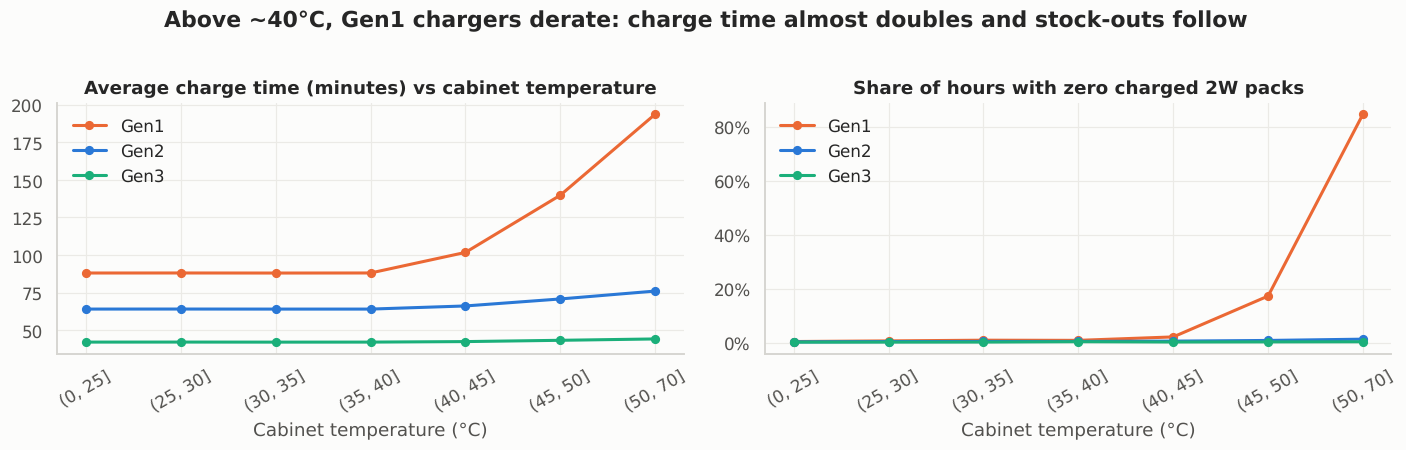

charger_generation   Gen1  Gen2  Gen3
cab_band                             
(0, 25]              88.0  64.0  42.0
(25, 30]             88.0  64.0  42.0
(30, 35]             88.0  64.0  42.0
(35, 40]             88.0  64.0  42.0
(40, 45]            101.7  66.1  42.4
(45, 50]            139.8  70.7  43.2
(50, 70]            193.7  76.0  44.1


In [30]:
ct = h.pivot_table(index='cab_band', columns='charger_generation', values='avg_charge_minutes', aggfunc='mean', observed=True)
so = h.pivot_table(index='cab_band', columns='charger_generation', values='stockout_2w', aggfunc='mean', observed=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g in ['Gen1', 'Gen2', 'Gen3']:
    axes[0].plot(ct.index.astype(str), ct[g], marker='o', ms=5, color=GEN_COL[g], label=g)
    axes[1].plot(so.index.astype(str), so[g], marker='o', ms=5, color=GEN_COL[g], label=g)
axes[0].set_title('Average charge time (minutes) vs cabinet temperature'); axes[0].set_xlabel('Cabinet temperature (°C)')
axes[1].set_title('Share of hours with zero charged 2W packs'); axes[1].yaxis.set_major_formatter(pct); axes[1].set_xlabel('Cabinet temperature (°C)')
for a in axes: a.legend(frameon=False); a.tick_params(axis='x', rotation=30)
fig.suptitle('Above ~40°C, Gen1 chargers derate: charge time almost doubles and stock-outs follow', fontweight='bold', y=1.02)
fig.tight_layout(); save(fig, '06_thermal_derating'); plt.show()
print(ct.round(1))

In [31]:
# Which cities run hottest, and how many Gen1 stations does each have?
heat = city_daily.assign(mon=city_daily.date.dt.month).query('mon in [4,5,6]').groupby('city').agg(summer_max_temp=('max_temp_c', 'mean'), heat_alert_days=('heat_alert', 'sum'))
gen_mix = pd.crosstab(stations.city, stations.charger_generation)
pd.concat([heat, gen_mix, swaps[swaps.season.str.startswith('Summer')].groupby('city').failed.mean().rename('summer_failure_rate')], axis=1).round(3)

,summer_max_temp,heat_alert_days,Gen1,Gen2,Gen3,summer_failure_rate
city,,,,,,
Bengaluru,32.454,0,9,16,7,0.049
Delhi NCR,40.483,62,13,10,7,0.126
Hyderabad,37.665,16,13,6,7,0.108
Jaipur,41.164,72,10,3,5,0.140
Mumbai,31.225,0,2,15,5,0.045
Pune,33.867,0,4,12,6,0.060


**Q3 answer: charger generation is the dominant station attribute, and it interacts with heat and city.**
- **Turnaround**: Gen1 cabinets take about 88 minutes to charge a pack in normal conditions vs 64 (Gen2) and 42 (Gen3). Above about 40°C cabinet temperature, Gen1 charge time climbs to ~140 minutes at 45-50°C and ~190 minutes above 50°C, and the share of hours with zero charged 2W packs shoots up. Gen2/Gen3 are almost unaffected. Packs are also quarantined for thermal reasons above 40°C at every generation.
- **Geography**: Jaipur (41°C average summer max, 72 heat-alert days), Delhi NCR (40°C, 62) and Hyderabad (38°C, 16) combine the hottest summers with the most Gen1 stations (36 of 51). Their summer failure rates are 14.0%, 12.6% and 10.8%, versus 4.5-6.0% in Bengaluru, Mumbai and Pune.
- **Location type** matters much less once generation is accounted for. Commercial hubs and markets look worse mainly because most Gen1 launch stations sit there; highway fuel pumps (where much of Wave 1 went) look good partly because they are quieter.
- **Commissioning wave**: Wave 1 (Gen2/Gen3) and Wave 2 (all Gen3) stations have near-zero stock-outs, but they were spread across all cities rather than targeted at the Gen1 hot spots (see D1).
- **Complaints**: compared within the same period (H1 2025), Gen1 stations generate about 150 tickets per 10,000 attempts vs about 113-124 at Gen2/Gen3, and the three hot cities generate the most tickets per attempt.

### Q4. Battery and equipment performance
How does battery health (SOH, cycles, supplier, lot) relate to delivered range and swap frequency? Do any cohorts stand out?

In [32]:
k2 = comp[(comp.vehicle_class == '2W') & comp.km_clean.notna()].copy()
k2['soh_band'] = pd.cut(k2.soh_in_pct, [50, 60, 70, 75, 80, 85, 90, 95, 100])
rng = k2.groupby('soh_band', observed=True).agg(swaps=('event_id', 'size'), km_per_pack=('km_clean', 'mean'), kwh_to_recharge=('energy_to_recharge_kwh', 'mean'))
r, p = stats.pearsonr(k2.soh_in_pct, k2.km_clean)
print(f'2W: correlation between returned-pack SOH and km covered: r = {r:.2f} (p < 0.001, n = {len(k2):,})')
rng.round(2)

2W: correlation between returned-pack SOH and km covered: r = 0.71 (p < 0.001, n = 3,201,398)


,swaps,km_per_pack,kwh_to_recharge
soh_band,,,
"(50, 60]",7385,34.94,1.51
"(60, 70]",145404,38.14,1.55
"(70, 75]",86484,43.13,1.64
"(75, 80]",143364,48.77,1.67
"(80, 85]",651861,53.43,1.67
"(85, 90]",788860,57.49,1.81
"(90, 95]",767507,63.05,1.93
"(95, 100]",610533,67.36,2.02


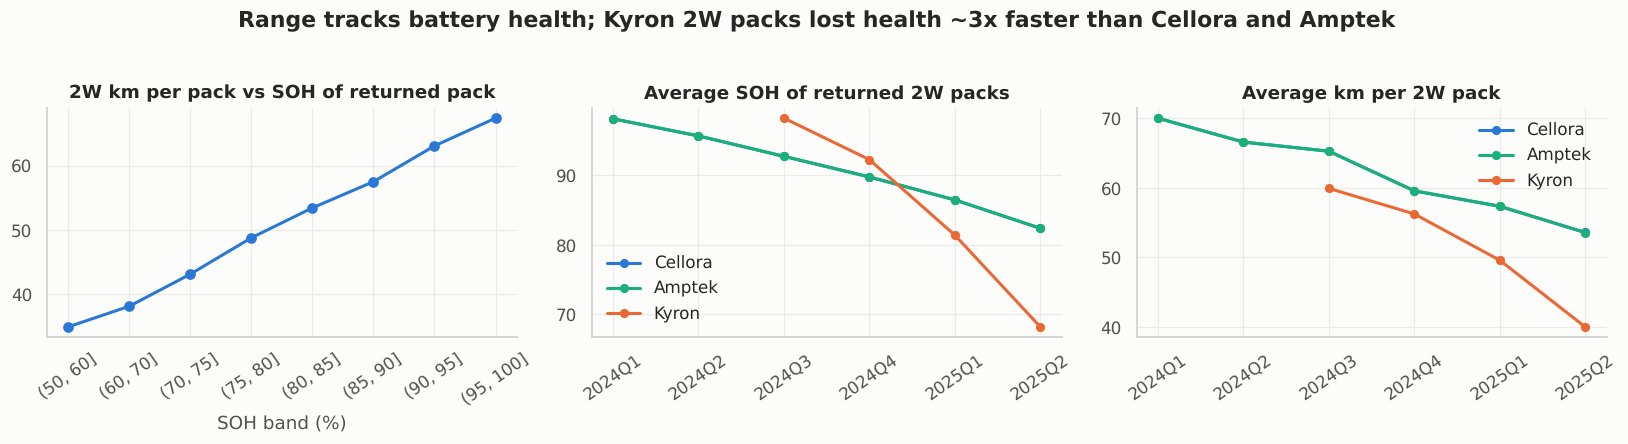

In [33]:
k2['quarter'] = k2.event_ts.dt.to_period('Q').astype(str)
sup_q_soh = k2.pivot_table(index='quarter', columns='sup_in', values='soh_in_pct', aggfunc='mean')
sup_q_km = k2.pivot_table(index='quarter', columns='sup_in', values='km_clean', aggfunc='mean')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].plot(rng.index.astype(str), rng.km_per_pack, marker='o', color=PAL[0]); axes[0].tick_params(axis='x', rotation=35)
axes[0].set_title('2W km per pack vs SOH of returned pack'); axes[0].set_xlabel('SOH band (%)')
for sname in ['Cellora', 'Amptek', 'Kyron']:
    axes[1].plot(sup_q_soh.index, sup_q_soh[sname], marker='o', ms=5, color=SUP_COL[sname], label=sname)
    axes[2].plot(sup_q_km.index, sup_q_km[sname], marker='o', ms=5, color=SUP_COL[sname], label=sname)
axes[1].set_title('Average SOH of returned 2W packs'); axes[2].set_title('Average km per 2W pack')
for a in axes[1:]: a.legend(frameon=False); a.tick_params(axis='x', rotation=35)
fig.suptitle('Range tracks battery health; Kyron 2W packs lost health ~3x faster than Cellora and Amptek', fontweight='bold', y=1.03)
fig.tight_layout(); save(fig, '07_battery_range'); plt.show()

In [34]:
cohort = batteries.groupby(['pack_type', 'supplier']).agg(packs=('battery_id', 'size'), first_commission=('commission_date', 'min'),
                                                          swaps_per_pack=('n_swaps', 'mean'), soh_now=('last_soh', 'mean'),
                                                          soh_pts_per_100_swaps=('soh_per_swap', lambda x: 100 * x.median()),
                                                          retired_share=('retired_date', lambda x: x.notna().mean()),
                                                          purchase_cost=('purchase_cost_inr', 'mean'), wear_inr_per_swap=('wear_inr_per_swap', 'mean'))
cohort.round(2)

packs first_commission  swaps_per_pack  soh_now  soh_pts_per_100_swaps  retired_share  purchase_cost  wear_inr_per_swap
pack_type supplier                                                                                                                         
2W_2.1kWh Amptek     1098       2024-03-01          643.06    79.99                   2.99           0.00       31995.05              24.91
          Cellora    3035       2023-03-01          643.15    79.97                   2.98           0.00       31983.39              24.88
          Kyron      1385       2024-09-10          401.71    60.58                   9.62           1.00       31981.68              80.21
3W_4.8kWh Amptek      209       2024-03-01          377.38    86.53                   3.37           0.00       67822.26              59.51
          Cellora     520       2023-03-01          378.66    86.54                   3.35           0.00       67957.39              59.35
          Kyron       253       2024-07-01          381.38    81.35                   3.50           0.21       67920.95              61.96

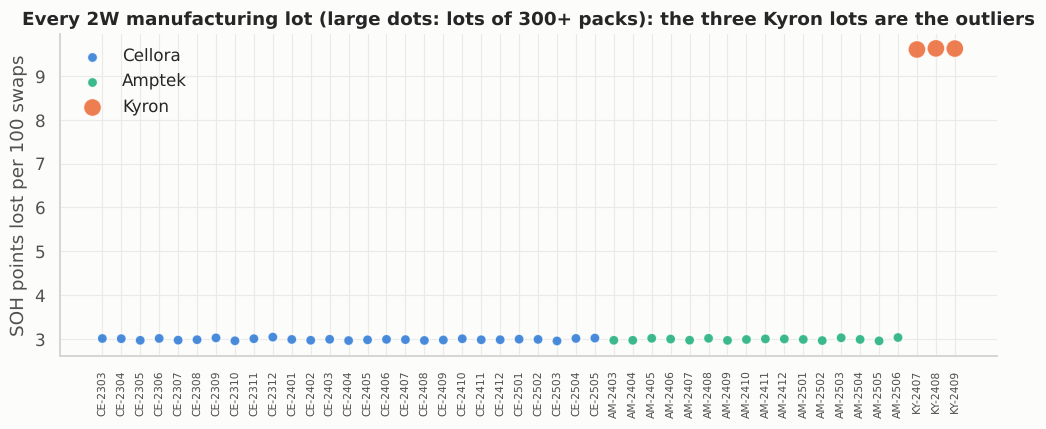

,supplier,manufacturing_lot,packs,soh_pts_per_100_swaps,soh_now,retired
44,Kyron,KY-2408,471,9.63,60.59,1.0
45,Kyron,KY-2409,462,9.63,60.62,1.0
43,Kyron,KY-2407,452,9.61,60.54,1.0
25,Cellora,CE-2312,121,3.04,79.88,0.0
15,Amptek,AM-2506,38,3.03,79.99,0.0
12,Amptek,AM-2503,75,3.02,79.97,0.0
22,Cellora,CE-2309,112,3.02,79.90,0.0
42,Cellora,CE-2505,106,3.02,79.93,0.0


In [35]:
lots = batteries[batteries.pack_type.str.startswith('2W')].groupby(['supplier', 'manufacturing_lot']).agg(packs=('battery_id', 'size'), soh_pts_per_100_swaps=('soh_per_swap', lambda x: 100 * x.median()),
                                                                                                    soh_now=('last_soh', 'mean'), retired=('retired_date', lambda x: x.notna().mean())).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.8))
for sname in ['Cellora', 'Amptek', 'Kyron']:
    d = lots[lots.supplier == sname]
    ax.scatter(d.manufacturing_lot, d.soh_pts_per_100_swaps, s=np.where(d.packs > 300, 140, 45), color=SUP_COL[sname], label=sname, alpha=0.85, edgecolor='white', linewidth=1)
ax.set_ylabel('SOH points lost per 100 swaps'); ax.tick_params(axis='x', rotation=90, labelsize=7); ax.legend(frameon=False)
ax.set_title('Every 2W manufacturing lot (large dots: lots of 300+ packs): the three Kyron lots are the outliers')
save(fig, '08_lots'); plt.show()
lots.sort_values('soh_pts_per_100_swaps', ascending=False).head(8).round(2)

In [36]:
# Swap frequency: do riders handed weaker packs come back sooner?
c2 = comp[comp.vehicle_class == '2W'].sort_values(['rider_id', 'event_ts'])[['rider_id', 'event_ts', 'soh_out_pct']].copy()
c2['hours_to_next'] = (c2.groupby('rider_id').event_ts.shift(-1) - c2.event_ts).dt.total_seconds() / 3600
c2 = c2[c2.hours_to_next.between(0.1, 48)]
freq = c2.groupby(pd.cut(c2.soh_out_pct, [50, 65, 75, 85, 95, 100]), observed=True).hours_to_next.agg(['median', 'size'])
print('Hours until the rider\'s next swap, by SOH of the pack they received (2W):'); freq.round(2)

Hours until the rider's next swap, by SOH of the pack they received (2W):


,median,size
soh_out_pct,,
"(50, 65]",17.14,50686
"(65, 75]",17.37,117345
"(75, 85]",18.57,724142
"(85, 95]",19.50,1426791
"(95, 100]",20.71,512268


In [37]:
# Retired Kyron packs: are any still being issued after retirement?
ret = batteries.dropna(subset=['retired_date']).set_index('battery_id').retired_date
after = comp[comp.battery_out_id.isin(ret.index)]
after = after[after.event_ts > after.battery_out_id.map(ret)]
print(f'Packs marked retired: {len(ret):,} (all {batteries.loc[batteries.retired_date.notna(), "supplier"].unique()}), retirement date(s): {ret.dt.date.unique()}')
print(f'Swaps issuing a pack AFTER its recorded retirement date: {len(after):,} across {after.battery_out_id.nunique():,} packs')

Packs marked retired: 1,438 (all ['Kyron']), retirement date(s): [datetime.date(2025, 6, 15)]
Swaps issuing a pack AFTER its recorded retirement date: 36,109 across 1,438 packs


**Q4 answer: battery health drives delivered range, and one supplier cohort stands out sharply.**
- **Range follows health** (r = 0.71 across 3.2M 2W swaps): a pack returned at 95-100% SOH covered about 67 km; at 60-70% SOH, about 38 km. Network-wide, the average 2W pack delivered about 70 km in Q1 2024 and about 49 km in Q2 2025.
- **Swap frequency follows health too**: riders handed a pack below 65% SOH come back after a median of about 17 hours vs about 21 hours for a 95%+ pack, so weak packs add load to stations exactly when they are stretched.
- **Kyron 2W packs are the outlier.** The three Kyron lots KY-2407, KY-2408 and KY-2409 (~1,385 packs commissioned Sep-Nov 2024 to stock the Wave 1 expansion) lose about **9.6 SOH points per 100 swaps vs 3.0 for Cellora and Amptek**, over 3x faster. Their average SOH fell from 98% to 68% within three quarters, and by Q2 2025 they delivered about 40 km per pack vs about 54 km for other suppliers. Kyron **3W** packs degrade normally, so this is a 2W product or lot issue, not a supplier-wide one. Every other lot from every supplier sits at 3.0 ± 0.05 points.
- Cellora and Amptek are indistinguishable from each other. BMS firmware shows no relationship with degradation.
- **Asset-control gap**: all Kyron 2W packs were marked retired for end-of-life on 15 Jun 2025, yet **36,109 swaps after that date issued one of those retired packs**.
- **Cost impact**: costed per SOH point, a Kyron 2W pack costs about ₹80 of wear per swap vs about ₹25 for Cellora/Amptek. This is the main reason CM2 fell (Q1).

### Q5. Pricing and partner economics
The base price change, the peak/off-peak pilot, and fleet contract terms.

In [38]:
ind = comp[comp.segment == 'Independent']
print('Independent list price by vehicle class, Jun vs Jul 2024:')
print(ind[ind.month.astype(str).isin(['2024-06', '2024-07'])].groupby([ind.month.astype(str), 'vehicle_class'], observed=True).list_price_inr.mean().unstack())

# Volume response to the price rise: swaps per active rider per month, independent vs fleet riders
act = comp.groupby(['month', 'segment']).agg(swaps=('event_id', 'size'), riders=('rider_id', 'nunique'))
act['swaps_per_rider'] = act.swaps / act.riders
spr = act.swaps_per_rider.unstack()
pre, post = spr.loc['2024-04':'2024-06'].mean(), spr.loc['2024-07':'2024-09'].mean()
print('\nSwaps per active rider per month (Apr-Jun 2024 vs Jul-Sep 2024):')
print(pd.DataFrame({'pre': pre, 'post': post, 'change': post / pre - 1}).round(3))
did = (post['Independent'] / pre['Independent']) - (post['Fleet partner'] / pre['Fleet partner'])
print(f'Difference-in-differences (independent minus fleet): {did:+.1%}')

Independent list price by vehicle class, Jun vs Jul 2024:


vehicle_class    2W     3W
month                     
2024-06        60.0  100.0
2024-07        65.0  110.0



Swaps per active rider per month (Apr-Jun 2024 vs Jul-Sep 2024):
                  pre    post  change
segment                              
Fleet partner  24.805  26.364   0.063
Independent    20.180  21.695   0.075
Difference-in-differences (independent minus fleet): +1.2%


In [39]:
# Peak/off-peak pilot: Bengaluru and Pune from Oct 2024, independent riders only
pk_hours = sorted(comp.loc[comp.tariff_code == 'PEAK', 'hour'].unique())
print('PEAK tariff hours:', pk_hours, '| cities:', comp.loc[comp.tariff_code == 'PEAK', 'city'].unique().tolist(), '| start:', comp.loc[comp.tariff_code == 'PEAK', 'event_ts'].min().date())
print(comp[comp.tariff_code.isin(['PEAK', 'OFFPEAK', 'STD'])].groupby(['tariff_code', 'vehicle_class'], observed=True).amount_charged_inr.mean().unstack().round(1))
comp['pilot_city'] = comp.city.isin(['Bengaluru', 'Pune'])
billable = comp.partner_id.map(partners.set_index('partner_id').peak_surcharge_billable)
comp['price_segment'] = np.where(comp.partner_id.isna(), 'Independent', np.where(billable == 'Y', 'Fleet, surcharge billed to partner', 'Fleet, surcharge-exempt partner'))
comp['post_pilot'] = comp.event_ts >= '2024-10-01'
comp['peak_hour'] = comp.hour.isin(pk_hours)
did_tbl = []
for seg in ['Independent', 'Fleet, surcharge billed to partner', 'Fleet, surcharge-exempt partner']:
    d = comp[comp.price_segment == seg]
    for metric in ['peak_hour', 'amount_charged_inr']:
        t = d.groupby(['pilot_city', 'post_pilot'])[metric].mean().unstack()
        did_tbl.append({'segment': seg, 'metric': 'share of swaps in peak hours' if metric == 'peak_hour' else 'revenue per swap (₹)',
                        'pilot pre': t.loc[True, False], 'pilot post': t.loc[True, True], 'control pre': t.loc[False, False], 'control post': t.loc[False, True],
                        'DiD': (t.loc[True, True] - t.loc[True, False]) - (t.loc[False, True] - t.loc[False, False])})
print('Pilot-city fleet swaps, price paid in peak vs other hours, after Oct 2024:')
print(comp[comp.pilot_city & comp.post_pilot & (comp.segment == 'Fleet partner')].groupby(['price_segment', 'peak_hour']).amount_charged_inr.mean().unstack().round(1))
pd.DataFrame(did_tbl).round(4)

PEAK tariff hours: [np.int32(12), np.int32(13), np.int32(19), np.int32(20), np.int32(21), np.int32(22)] | cities: ['Bengaluru', 'Pune'] | start: 2024-10-01


vehicle_class    2W     3W
tariff_code               
STD            63.9  107.6
OFFPEAK        57.0  102.0
PEAK           80.0  125.0


Pilot-city fleet swaps, price paid in peak vs other hours, after Oct 2024:


peak_hour                           False  True 
price_segment                                   
Fleet, surcharge billed to partner   64.9   77.5
Fleet, surcharge-exempt partner      52.6   53.0


,segment,metric,pilot pre,pilot post,control pre,control post,DiD
0,Independent,share of swaps in peak hours,0.6174,0.5922,0.6135,0.6135,-0.0252
1,Independent,revenue per swap (₹),64.4537,75.3868,64.4430,67.3484,8.0276
2,"Fleet, surcharge billed to partner",share of swaps in peak hours,0.4885,0.4546,0.4561,0.4672,-0.0450
3,"Fleet, surcharge billed to partner",revenue per swap (₹),62.3000,70.5852,62.4123,64.9813,5.7162
4,"Fleet, surcharge-exempt partner",share of swaps in peak hours,0.7401,0.7324,0.7377,0.7362,-0.0061
5,"Fleet, surcharge-exempt partner",revenue per swap (₹),57.2267,52.8508,57.2772,52.7153,0.1860


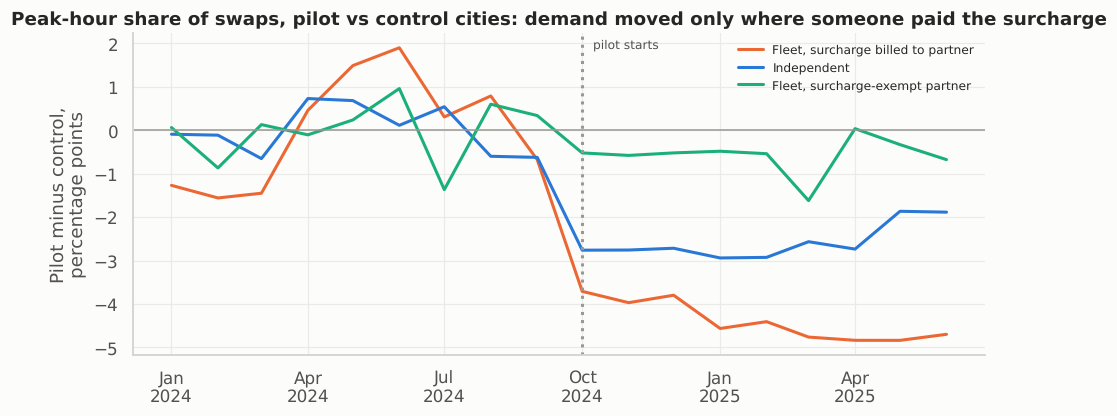

In [40]:
# Peak-hour share by month, independent riders, pilot vs control cities
# Peak-hour share in pilot cities minus control cities, by month and pricing segment
gap = comp.groupby(['month', 'price_segment', 'pilot_city']).peak_hour.mean().unstack()
gap = (gap[True] - gap[False]).unstack()
gap = gap - gap.loc['2024-01':'2024-09'].mean()          # index each line to its own pre-pilot level
fig, ax = plt.subplots(figsize=(10, 3.8))
xx = gap.index.to_timestamp()
for i, seg in enumerate(['Fleet, surcharge billed to partner', 'Independent', 'Fleet, surcharge-exempt partner']):
    ax.plot(xx, gap[seg] * 100, color=[PAL[1], PAL[0], PAL[2]][i], label=seg)
ax.axvline(pd.Timestamp('2024-10-01'), color=GREY, ls=':'); ax.axhline(0, color=GREY, lw=1)
ax.text(pd.Timestamp('2024-10-08'), ax.get_ylim()[1] * 0.85, 'pilot starts', fontsize=8, color='#52514e')
ax.set_ylabel('Pilot minus control,\npercentage points'); ax.legend(frameon=False, fontsize=8); fmt_dates(ax)
ax.set_title('Peak-hour share of swaps, pilot vs control cities: demand moved only where someone paid the surcharge')
save(fig, '09_pilot'); plt.show()

In [41]:
# Fleet partner contract economics
fp = comp[comp.segment == 'Fleet partner'].groupby('partner_id').agg(swaps=('event_id', 'size'), revenue_inr=('amount_charged_inr', 'sum'), revenue_per_swap=('amount_charged_inr', 'mean'),
                                                                     energy=('energy_cost', 'mean'), site=('site_cost', 'mean'), wear=('wear_cost', 'mean'),
                                                                     cm1=('cm1', 'mean'), cm2=('cm2', 'mean'), cm2_total=('cm2', 'sum'))
fp = partners.set_index('partner_id')[['partner_name', 'partner_segment', 'vehicle_class', 'contract_type', 'discount_pct', 'discount_pct_after_amendment', 'peak_surcharge_billable', 'payment_terms_days']].join(fp)
fp['revenue_share'] = fp.revenue_inr / fp.revenue_inr.sum()
indep_row = comp[comp.segment == 'Independent'].agg({'amount_charged_inr': 'mean', 'cm1': 'mean', 'cm2': 'mean'})
print(f'Independent riders for reference: revenue/swap ₹{indep_row.amount_charged_inr:.1f}, CM1 ₹{indep_row.cm1:.1f}, CM2 ₹{indep_row.cm2:.1f}')
fp.sort_values('revenue_inr', ascending=False).round(2)

Independent riders for reference: revenue/swap ₹68.2, CM1 ₹36.6, CM2 ₹0.6


,partner_name,partner_segment,vehicle_class,contract_type,discount_pct,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,swaps,revenue_inr,revenue_per_swap,energy,site,wear,cm1,cm2,cm2_total,revenue_share
partner_id,,,,,,,,,,,,,,,,,,
FP-01,FeastFly,food_delivery,2W,volume_tiered,10.0,NaN,Y,30,516367,32027884.50,62.03,18.21,13.44,35.73,30.38,-5.36,-2766092.96,0.22
FP-03,ZipDrop,quick_commerce,2W,volume_tiered,12.0,28.0,N,45,549390,28606514.80,52.07,19.14,12.84,35.91,20.09,-15.82,-8693308.76,0.20
FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,15.0,NaN,Y,30,296209,16740212.75,56.51,18.13,13.52,36.01,24.87,-11.14,-3300111.02,0.11
FP-05,Swiggle Go,food_delivery,2W,volume_tiered,11.0,NaN,N,30,237632,14092428.90,59.30,18.36,13.55,35.71,27.39,-8.32,-1977000.51,0.10
FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,8.0,NaN,Y,30,131334,13062630.80,99.46,40.80,13.78,60.06,44.88,-15.18,-1993137.13,0.09
FP-07,QuickCart,quick_commerce,2W,pay_per_swap,9.0,NaN,Y,30,127961,7934508.55,62.01,17.89,13.66,35.07,30.46,-4.61,-589594.82,0.05
FP-06,RideMitra,bike_taxi,2W,pay_per_swap,6.0,NaN,Y,15,119503,7494595.50,62.71,17.94,13.83,35.79,30.95,-4.84,-578961.22,0.05
FP-08,DabbaXpress,food_delivery,2W,pay_per_swap,8.0,NaN,Y,30,92027,5853723.60,63.61,18.06,13.21,36.00,32.35,-3.65,-335983.63,0.04
FP-09,HaulKing,cargo_3w,3W,pay_per_swap,7.0,NaN,Y,45,53120,5331093.20,100.36,40.77,13.87,60.07,45.72,-14.35,-762006.80,0.04


ZipDrop revenue per swap: Jul-Oct 2024 ₹59.7 -> Nov 2024-Feb 2025 ₹48.7
ZipDrop monthly swaps:    Jul-Oct 2024 27,048 -> Nov 2024-Feb 2025 38,890
Revenue given up through the amendment, Nov 2024-Jun 2025: ₹3.7 million


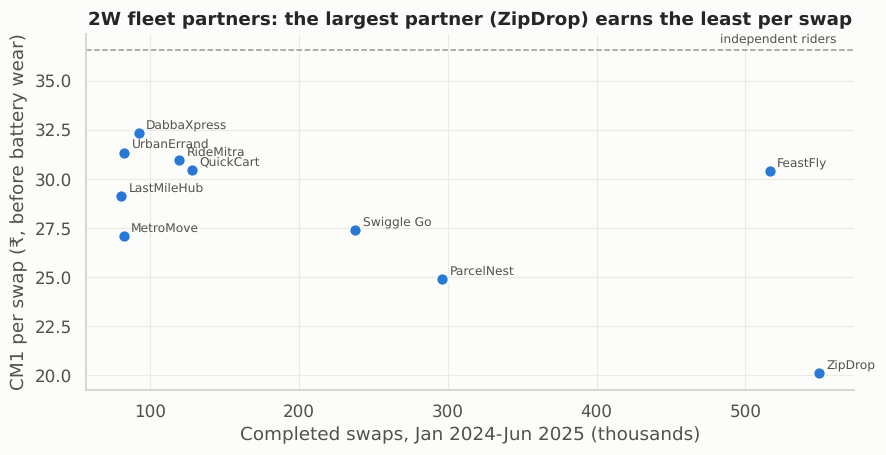

In [42]:
z = comp[comp.partner_id == 'FP-03'].groupby('month').agg(swaps=('event_id', 'size'), revenue_per_swap=('amount_charged_inr', 'mean'), cm1=('cm1', 'mean'))
pre_z, post_z = z.loc['2024-07':'2024-10'], z.loc['2024-11':'2025-02']
print(f"ZipDrop revenue per swap: Jul-Oct 2024 ₹{pre_z.revenue_per_swap.mean():.1f} -> Nov 2024-Feb 2025 ₹{post_z.revenue_per_swap.mean():.1f}")
print(f"ZipDrop monthly swaps:    Jul-Oct 2024 {pre_z.swaps.mean():,.0f} -> Nov 2024-Feb 2025 {post_z.swaps.mean():,.0f}")
lost = (pre_z.revenue_per_swap.mean() - z.loc['2024-11':].revenue_per_swap.mean()) * z.loc['2024-11':].swaps.sum()
print(f'Revenue given up through the amendment, Nov 2024-Jun 2025: ₹{lost/1e6:.1f} million')

fig, ax = plt.subplots(figsize=(9, 4.2))
d2 = fp[fp.vehicle_class != '3W'].sort_values('cm1')
ax.scatter(d2.swaps / 1e3, d2.cm1, s=60, color=PAL[0], edgecolor='white', zorder=3)
for pid, r_ in d2.iterrows():
    ax.annotate(r_.partner_name, (r_.swaps / 1e3, r_.cm1), xytext=(5, 3), textcoords='offset points', fontsize=8, color='#52514e')
ax.axhline(indep_row.cm1, color=GREY, ls='--', lw=1); ax.text(ax.get_xlim()[1] * 0.98, indep_row.cm1 + 0.4, 'independent riders', ha='right', fontsize=8, color='#52514e')
ax.set_xlabel('Completed swaps, Jan 2024-Jun 2025 (thousands)'); ax.set_ylabel('CM1 per swap (₹, before battery wear)')
ax.set_title('2W fleet partners: the largest partner (ZipDrop) earns the least per swap')
save(fig, '10_partners'); plt.show()

**Q5 answer: pricing helped revenue, contract terms set the margin, and segments respond very differently.**
- **Base price change (1 Jul 2024)**: list price rose from ₹60 to ₹65 (2W) and ₹100 to ₹110 (3W). Swaps per active rider rose for both independent and fleet riders over the next quarter, and the difference-in-differences is +1.2%, so there is **no sign of lost volume**. This was the single best margin move in the period.
- **Peak/off-peak pilot (Bengaluru and Pune, from 1 Oct 2024)**: peak hours are 12:00-14:00 and 19:00-23:00. A 2W independent rider pays ₹80 at peak vs ₹57 off-peak (₹64 standard). The effect depends on **who sees the surcharge**:
  - *Independent riders*: peak-hour share fell 2.5 points vs control cities; revenue per swap +₹8.0 (difference-in-differences).
  - *Fleet riders whose partner is billed the surcharge* (10 of 12 partners): peak share fell 4.5 points and revenue per swap +₹5.7. Partners who pay for peak swaps actively move their riders' schedules.
  - *Riders of surcharge-exempt partners* (ZipDrop, Swiggle Go): no change (−0.6 points, ₹0.2).
  - So the pilot **does shift demand, but only for payers exposed to the price**. Rolled out network-wide with the current exemptions, it would leave the largest fleet volume untouched.
- **Fleet contracts**: partner riders are about two-thirds of swaps. **ZipDrop (FP-03)** renegotiated its discount from 12% to 28% in Nov 2024 and is exempt from the peak surcharge. Its revenue per swap fell from ₹59.7 to ₹48.7, giving up about ₹3.7M of revenue in eight months, and it is now **#2 by revenue but last of 12 partners on margin per swap** (CM1 ₹20 vs ₹30 for FeastFly and ₹37 for independent riders). Its volume kept growing at the same pace it had before the amendment, so there is no evidence the deeper discount bought extra volume.
- 3W cargo partners (CargoTuk, HaulKing) earn the highest CM1 per swap but carry heavy energy and wear, and their riders suffer twice the failure rate.

### Q6. Root cause analysis of new-rider retention
**Definitions.** A *new rider* signed up in 2024 or 2025 and made a first swap attempt by 30 Apr 2025 (so a 60-day follow-up window is fully observed). The rider is **retained** if they complete at least one swap on days 30-59 after their first attempt, and **churned** otherwise. Their *first-14-day experience* is measured from their own attempts.

In [43]:
first = swaps.groupby('rider_id', observed=True).event_ts.min().rename('first_ts')
nr = riders.merge(first, left_on='rider_id', right_index=True)
nr = nr[(nr.signup_date >= '2024-01-01') & (nr.first_ts <= '2025-04-30')].copy()
sw_nr = swaps[swaps.rider_id.isin(nr.rider_id)][['rider_id', 'event_ts', 'completed', 'failed', 'no_battery', 'abandoned', 'soh_out_pct', 'km_clean', 'queue_wait_sec', 'charger_generation', 'city', 'amount_charged_inr']].copy()
sw_nr['rider_id'] = sw_nr.rider_id.astype(str)
sw_nr = sw_nr.merge(nr[['rider_id', 'first_ts']], on='rider_id')
sw_nr['day'] = (sw_nr.event_ts - sw_nr.first_ts).dt.total_seconds() / 86400
retained = sw_nr[sw_nr.completed & sw_nr.day.between(30, 60, inclusive='left')].rider_id.unique()
w14 = sw_nr[sw_nr.day < 14]
feat = w14.groupby('rider_id').agg(attempts_14d=('failed', 'size'), fails_14d=('failed', 'sum'), no_battery_14d=('no_battery', 'sum'),
                                   abandons_14d=('abandoned', 'sum'), soh_received=('soh_out_pct', 'mean'), km_per_pack=('km_clean', 'mean'),
                                   queue_s=('queue_wait_sec', 'mean'), gen1_share=('charger_generation', lambda x: (x == 'Gen1').mean()),
                                   main_city=('city', lambda x: x.mode().iloc[0]))
nr = nr.merge(feat, left_on='rider_id', right_index=True, how='left')
nr['churned'] = (~nr.rider_id.isin(retained)).astype(int)
nr['first_month'] = nr.first_ts.dt.to_period('M')
nr['summer_start'] = nr.first_ts.dt.month.isin([4, 5, 6]).astype(int)
nr['multi_fail'] = (nr.fails_14d >= 2).astype(int)
nr['low_soh'] = (nr.soh_received < 85).astype(int)
nr['segment'] = np.where(nr.partner_id.isna(), 'Independent', 'Fleet partner')
dlo = city_daily[city_daily.competitor_promo_active]
promo_city_months = set(zip(dlo.city, dlo.date.dt.to_period('M')))
nr['competitor_promo'] = [int((c, m) in promo_city_months) for c, m in zip(nr.main_city, nr.first_month)]
print(f'New riders analysed: {len(nr):,}   overall 30-60 day churn: {nr.churned.mean():.1%}')

New riders analysed: 13,751   overall 30-60 day churn: 14.6%


first_month
2024-01    0.149
2024-02    0.148
2024-03    0.115
2024-04    0.176
2024-05    0.209
2024-06    0.163
2024-07    0.121
2024-08    0.125
2024-09    0.143
2024-10    0.145
2024-11    0.129
2024-12    0.134
2025-01    0.130
2025-02    0.133
2025-03    0.150
2025-04    0.180
Freq: M


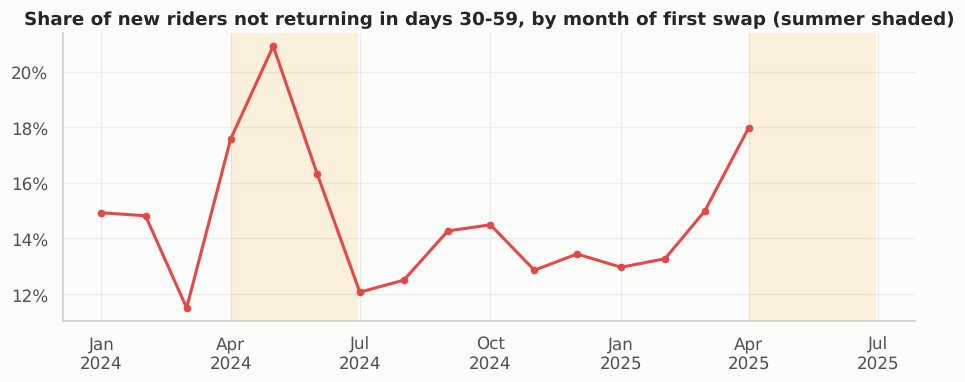

In [44]:
coh = nr.groupby('first_month').churned.mean()
print(coh.round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(coh.index.to_timestamp(), coh.values, marker='o', ms=4, color=PAL[7])
for yr in ['2024', '2025']:
    ax.axvspan(pd.Timestamp(f'{yr}-04-01'), pd.Timestamp(f'{yr}-06-30'), color=PAL[3], alpha=0.12, lw=0)
ax.yaxis.set_major_formatter(pct); fmt_dates(ax); ax.set_title('Share of new riders not returning in days 30-59, by month of first swap (summer shaded)')
save(fig, '11_cohort_churn'); plt.show()

In [45]:
def churn_by(col, bins=None, labels=None):
    g = pd.cut(nr[col], bins, labels=labels) if bins is not None else nr[col]
    return nr.groupby(g, observed=True).churned.agg(churn_rate='mean', riders='size')
tbls = {
    'Failed attempts in first 14 days': churn_by('fails_14d', [-1, 0, 1, 2, 4, 100], ['0', '1', '2', '3-4', '5+']),
    'Avg SOH of packs received, first 14 days': churn_by('soh_received', [0, 80, 85, 90, 95, 101], ['<80', '80-85', '85-90', '90-95', '95+']),
    'Share of first-14-day attempts at Gen1': churn_by('gen1_share', [-0.01, 0, 0.5, 0.99, 1], ['none', '<50%', '50-99%', 'all']),
    'Started in summer': churn_by('summer_start'),
    'Segment': churn_by('segment'),
    'Vehicle class': churn_by('vehicle_class'),
    'Signup channel': churn_by('signup_channel'),
    'Main city': churn_by('main_city'),
}
for k_, v in tbls.items():
    print('\n' + k_); print(v.round(3).to_string())


Failed attempts in first 14 days
           churn_rate  riders
fails_14d                    
0               0.133    6914
1               0.128    4339
2               0.205    1666
3-4             0.223     741
5+              0.275      91

Avg SOH of packs received, first 14 days
              churn_rate  riders
soh_received                    
<80                0.215     353
80-85              0.142    1714
85-90              0.133    3099
90-95              0.137    5109
95+                0.163    3472

Share of first-14-day attempts at Gen1
            churn_rate  riders
gen1_share                    
none             0.156    2735
<50%             0.126    4130
50-99%           0.132    4142
all              0.186    2744

Started in summer
              churn_rate  riders
summer_start                    
0                  0.135   10595
1                  0.182    3156

Segment
               churn_rate  riders
segment                          
Fleet partner       0.155    

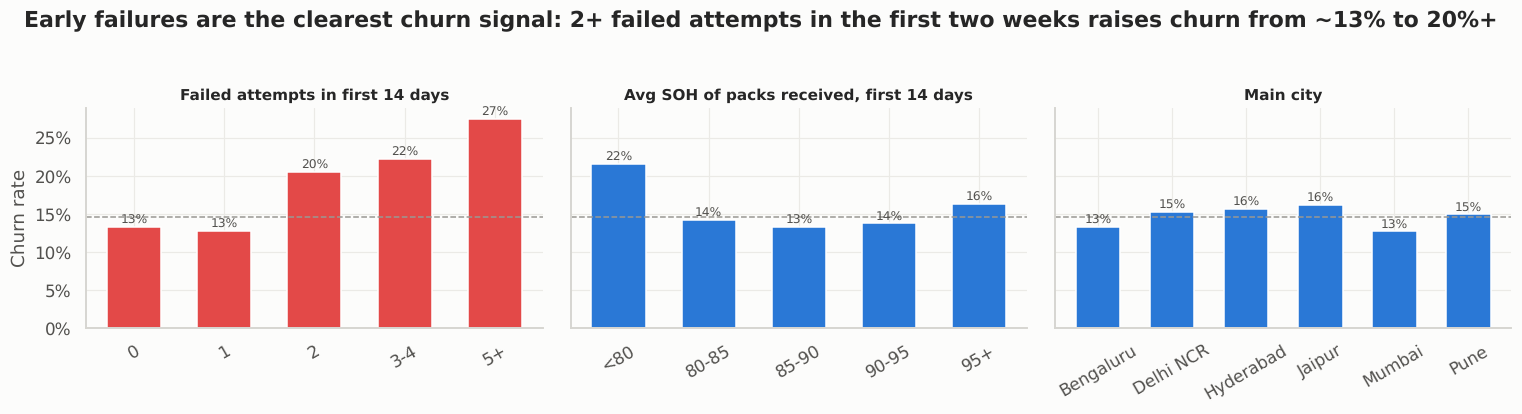

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, key in zip(axes, ['Failed attempts in first 14 days', 'Avg SOH of packs received, first 14 days', 'Main city']):
    v = tbls[key]
    a.bar(v.index.astype(str), v.churn_rate, color=PAL[7] if key.startswith('Failed') else PAL[0], width=0.6)
    a.axhline(nr.churned.mean(), color=GREY, ls='--', lw=1); a.set_title(key, fontsize=10); a.tick_params(axis='x', rotation=30)
    for i, val in enumerate(v.churn_rate): a.text(i, val + 0.004, f'{val:.0%}', ha='center', fontsize=8, color='#52514e')
axes[0].yaxis.set_major_formatter(pct); axes[0].set_ylabel('Churn rate')
fig.suptitle('Early failures are the clearest churn signal: 2+ failed attempts in the first two weeks raises churn from ~13% to 20%+', fontweight='bold', y=1.04)
fig.tight_layout(); save(fig, '12_churn_drivers'); plt.show()

In [47]:
# Multivariable logistic regression: which factors keep their association once the others are held constant?
md = nr.dropna(subset=['soh_received', 'attempts_14d']).copy()
md['log_attempts'] = np.log(md.attempts_14d)
model = smf.logit('churned ~ multi_fail + low_soh + gen1_share + summer_start + competitor_promo + C(segment) + C(vehicle_class) '
                  '+ C(signup_channel) + C(main_city) + log_attempts', data=md).fit(disp=0)
res = model.summary2().tables[1]
res['odds_ratio'] = np.exp(res['Coef.'])
res['OR_low'] = np.exp(res['[0.025'])
res['OR_high'] = np.exp(res['0.975]'])
print(f'n = {int(model.nobs):,}   pseudo R² = {model.prsquared:.3f}')
res[['odds_ratio', 'OR_low', 'OR_high', 'P>|z|']].round(3)

n = 13,747   pseudo R² = 0.095


,odds_ratio,OR_low,OR_high,P>|z|
Intercept,7.137,4.738,10.751,0.000
C(segment)[T.Independent],0.612,0.478,0.784,0.000
C(vehicle_class)[T.3W],0.718,0.622,0.828,0.000
C(signup_channel)[T.field_agent],1.055,0.830,1.340,0.663
C(signup_channel)[T.partner_onboarding],0.998,0.754,1.320,0.987
C(signup_channel)[T.referral],1.084,0.898,1.310,0.402
C(main_city)[T.Delhi NCR],1.674,1.407,1.991,0.000
C(main_city)[T.Hyderabad],1.727,1.442,2.068,0.000
C(main_city)[T.Jaipur],1.769,1.452,2.155,0.000
C(main_city)[T.Mumbai],1.346,1.112,1.629,0.002


In [48]:
# Is the Gen1 / summer effect mediated by failures? Compare models with and without the failure variable.
m_nofail = smf.logit('churned ~ gen1_share + summer_start + C(main_city) + log_attempts', data=md).fit(disp=0)
m_fail = smf.logit('churned ~ multi_fail + gen1_share + summer_start + C(main_city) + log_attempts', data=md).fit(disp=0)
med = pd.DataFrame({'without failures': np.exp(m_nofail.params[['gen1_share', 'summer_start']]),
                    'with failures': np.exp(m_fail.params[['gen1_share', 'summer_start']])})
print('Odds ratios for Gen1 exposure and summer start, before vs after controlling for early failures:'); med.round(3)

Odds ratios for Gen1 exposure and summer start, before vs after controlling for early failures:


,without failures,with failures
gen1_share,1.066,1.024
summer_start,1.420,1.215


In [49]:
# Population attributable share: how much churn is associated with each experience factor?
base = nr.churned.mean()
paf = {}
for f_, cond in [('2+ failed attempts in 14 days', nr.multi_fail == 1), ('Avg SOH received < 85%', nr.low_soh == 1), ('Started in summer', nr.summer_start == 1)]:
    p_exp = cond.mean(); r1 = nr.loc[cond, 'churned'].mean(); r0 = nr.loc[~cond, 'churned'].mean()
    paf[f_] = {'exposed_share': p_exp, 'churn_exposed': r1, 'churn_unexposed': r0, 'relative_risk': r1 / r0, 'attributable_share_of_churn': p_exp * (r1 - r0) / base}
pd.DataFrame(paf).T.round(3)

,exposed_share,churn_exposed,churn_unexposed,relative_risk,attributable_share_of_churn
2+ failed attempts in 14 days,0.182,0.213,0.131,1.623,0.102
Avg SOH received < 85%,0.150,0.155,0.144,1.073,0.011
Started in summer,0.230,0.182,0.135,1.347,0.074


**Q6 answer: primary vs secondary drivers of new-rider churn.**

Of 13,751 new riders, 14.6% did not come back in their second month. Churn is highest for riders who start in late spring (21% for May 2024 starters) and is lowest for riders starting in cooler months (~12-13%).

| Tier | Factor | Evidence |
|---|---|---|
| **Primary** | **Failed swap attempts in the first two weeks** (mostly "no charged battery") | Clear dose-response: churn is 13% with 0-1 early failures, 20.5% with 2, 22% with 3-4 and 27.5% with 5+. Odds ratio 2.18 (95% CI 1.93-2.46) after controlling for city, segment, vehicle class, channel, battery health and activity. It accounts for about 10% of all churn on its own. |
| **Primary (upstream)** | **Summer heat at Gen1 stations** | The cause of those failures (Q2/Q3). Adding early failures to the model shrinks the summer odds ratio from 1.42 to 1.22 and removes the Gen1 effect almost entirely (1.07 → 1.02): Gen1 and summer matter *because* they cause failures. |
| **Secondary** | **Low battery health in the first weeks** | Riders whose packs averaged below 80% SOH churn at 21.5%; the <85% flag has an independent odds ratio of 1.20 (CI 1.04-1.39). Linked to the Kyron cohort (Q4). |
| **Secondary** | **City** | Delhi NCR, Hyderabad and Jaipur have 1.7-1.8x the odds of churn of Bengaluru after controls; this is consistent with hot-city operations beyond what the failure flag captures. |
| **Contextual** | **Segment** | Fleet riders churn more than independents (15.5% vs 13.1%; independent OR 0.61). Fleet riders are more peak-hour bound and have the rider-employer relationship in between. |
| **Not supported** | **Competitor promotions, signup channel** | Competitor promotions ran only in Bengaluru and Pune in Q1 2025 and show no association (OR 1.07, p = 0.61). Signup channel is not significant. |

The model explains only part of churn (pseudo R² ≈ 0.10), which is expected for individual behaviour. Observational data cannot prove causation, but the dose-response pattern, its persistence after controls, and the way failures absorb the Gen1 and summer effects make **early service failures the most credible primary driver**.

## 5. Optional deep dives

### D1. Expansion wave effectiveness: did new stations go where riders needed them?

In [50]:
pre_summer = swaps[(swaps.event_ts >= '2024-04-01') & (swaps.event_ts < '2024-07-01') & (swaps.expansion_wave == 'Launch')]
need = pre_summer.groupby('city').agg(summer24_failure_rate=('failed', 'mean'), summer24_failed_attempts=('failed', 'sum'))
added = stations.pivot_table(index='city', columns='expansion_wave', values='station_id', aggfunc='count').fillna(0)
gen1 = stations[stations.charger_generation == 'Gen1'].groupby('city').size().rename('gen1_stations')
exp = need.join(added).join(gen1)
exp['new_stations'] = exp['Wave1_2024H2'] + exp['Wave2_2025H1']
exp['share_of_failures_2024'] = exp.summer24_failed_attempts / exp.summer24_failed_attempts.sum()
exp['share_of_new_stations'] = exp.new_stations / exp.new_stations.sum()
print('Wave 1 location types:', stations[stations.expansion_wave == 'Wave1_2024H2'].location_type.value_counts().to_dict())
print('Wave 2 location types:', stations[stations.expansion_wave == 'Wave2_2025H1'].location_type.value_counts().to_dict())
exp.sort_values('share_of_failures_2024', ascending=False).round(3)

Wave 1 location types: {'highway_fuel_pump': 14, 'residential': 13, 'tech_park': 1, 'transit_hub': 1, 'commercial_hub': 1}
Wave 2 location types: {'market': 14, 'highway_fuel_pump': 5, 'transit_hub': 4, 'commercial_hub': 4, 'residential': 2, 'tech_park': 1}


,summer24_failure_rate,summer24_failed_attempts,Launch,Wave1_2024H2,Wave2_2025H1,gen1_stations,new_stations,share_of_failures_2024,share_of_new_stations
city,,,,,,,,,
Delhi NCR,0.145,11439,18,6,6,13,12,0.275,0.200
Hyderabad,0.127,9650,16,5,5,13,10,0.232,0.167
Jaipur,0.175,9401,10,4,4,10,8,0.226,0.133
Bengaluru,0.051,4329,20,6,6,9,12,0.104,0.200
Pune,0.064,4087,13,5,4,4,9,0.098,0.150
Mumbai,0.045,2703,13,4,5,2,9,0.065,0.150


In [51]:
# Did failure at the Launch stations improve from summer 2024 to summer 2025?
L = swaps[(swaps.expansion_wave == 'Launch') & swaps.mon.isin([4, 5, 6])]
L = L.assign(year=L.event_ts.dt.year)
yoy = L.pivot_table(index='city', columns='year', values='failed', aggfunc='mean')
yoy['change_pts'] = (yoy[2025] - yoy[2024]) * 100
yoy_gen = L.pivot_table(index='charger_generation', columns='year', values='failed', aggfunc='mean')
print('Summer failure rate at launch stations, 2024 vs 2025, by city:'); print(yoy.round(3))
print('\nBy charger generation:'); print(yoy_gen.round(3))

Summer failure rate at launch stations, 2024 vs 2025, by city:
year        2024   2025  change_pts
city                               
Bengaluru  0.051  0.050      -0.098
Delhi NCR  0.145  0.149       0.483
Hyderabad  0.127  0.124      -0.260
Jaipur     0.175  0.170      -0.517
Mumbai     0.045  0.045      -0.026
Pune       0.064  0.063      -0.111

By charger generation:
year                 2024   2025
charger_generation              
Gen1                0.131  0.128
Gen2                0.057  0.057


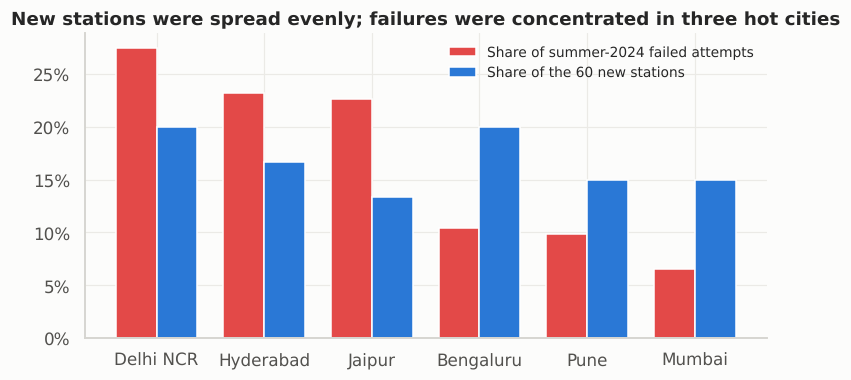

In [52]:
fig, ax = plt.subplots(figsize=(8, 3.6))
e2 = exp.sort_values('share_of_failures_2024', ascending=False)
xi = np.arange(len(e2)); wdt = 0.38
ax.bar(xi - wdt / 2, e2.share_of_failures_2024, wdt, color=PAL[7], label='Share of summer-2024 failed attempts')
ax.bar(xi + wdt / 2, e2.share_of_new_stations, wdt, color=PAL[0], label='Share of the 60 new stations')
ax.set_xticks(xi); ax.set_xticklabels(e2.index); ax.yaxis.set_major_formatter(pct); ax.legend(frameon=False, fontsize=9)
ax.set_title('New stations were spread evenly; failures were concentrated in three hot cities')
save(fig, '13_expansion'); plt.show()

**D1 answer.** The two waves added 60 Gen2/Gen3 stations spread roughly in proportion to existing network size. Wave 1 went mainly to **highway fuel pumps (14) and residential sites (13)**, the easiest locations to sign. Delhi NCR, Hyderabad and Jaipur produced **73% of summer-2024 failed attempts but received 50% of new stations**, while Bengaluru received 20% of new stations with 10% of failures. And **summer failure rates at Gen1 launch stations were unchanged** (13.1% in 2024, 12.8% in 2025). Expansion grew volume; it did not fix the stations where service was breaking.

### D2. The budget decision
Four proposals are on the table. The table below lines each one up against the evidence from Q1-Q6.

In [53]:
gen1_summer = swaps[(swaps.charger_generation == 'Gen1') & swaps.mon.isin([4, 5, 6])]
fail_excess = gen1_summer.failed.sum() - len(gen1_summer) * swaps[(swaps.charger_generation != 'Gen1') & swaps.mon.isin([4, 5, 6])].failed.mean()
kyron_wear = comp.loc[comp.sup_out == 'Kyron', 'wear_cost'].sum() - (comp.sup_out == 'Kyron').sum() * comp.loc[(comp.sup_out != 'Kyron') & (comp.vehicle_class == '2W'), 'wear_cost'].mean()
print(f'Excess failed attempts at Gen1 stations in summer (vs Gen2/3 rate): {fail_excess:,.0f} over two summers')
print(f'Excess battery wear cost of Kyron packs vs Cellora/Amptek: ₹{kyron_wear/1e6:,.1f} million')
print(f'ZipDrop revenue given up by the Nov 2024 amendment (to Jun 2025): ₹{lost/1e6:,.1f} million')

Excess failed attempts at Gen1 stations in summer (vs Gen2/3 rate): 45,087 over two summers
Excess battery wear cost of Kyron packs vs Cellora/Amptek: ₹34.4 million
ZipDrop revenue given up by the Nov 2024 amendment (to Jun 2025): ₹3.7 million


| Proposal | What the evidence says | Verdict |
|---|---|---|
| **More stations** | Waves 1-2 added volume but were placed where sites were easy, not where failures were; Gen1 hot-city failure rates did not improve. | **Not as proposed.** Retrofit or replace Gen1 cabinets in Delhi NCR, Jaipur and Hyderabad first (or add Gen3 capacity *next to* those stations). |
| **More batteries** | Stock-outs come from slow, heat-derated charging, not from too few packs: Gen2/Gen3 stations with similar inventory almost never run out. But battery *quality* matters: Kyron 2W packs cut range and inflate wear. | **Partly.** Buy replacement packs for the Kyron 2W cohort (from Cellora/Amptek) and add 3W packs at the stations with the most 3W stock-outs; do not just add volume. |
| **Network-wide peak pricing** | It raises revenue and does shift 2.5-4.5 points of demand off-peak, but only where the payer sees the surcharge. Exempt partners (ZipDrop, Swiggle Go: about a quarter of all swaps) do not move, and off-peak shifting cannot fix Gen1 heat derating, which happens in the afternoon too. | **Yes, but conditional.** Roll out first to the hot Gen1 cities, and only after removing surcharge exemptions from partner contracts. |
| **Long-term exclusive with the largest fleet partner** | ZipDrop is the largest partner by volume but the lowest-margin 2W partner after the 28% discount, with longer payment terms (45 days) and no peak surcharge. | **No.** Renegotiate toward the 10-15% norm with volume tiers or service-level-linked pricing before any exclusivity. |

### D3. Fleet partner value beyond revenue
Covered in Q5: ranking partners by contribution margin instead of revenue reverses the picture. ZipDrop is #2 by revenue but last among 2W partners on margin per swap.

In [54]:
fp_rank = fp[['partner_name', 'revenue_inr', 'cm1', 'cm2', 'cm2_total', 'payment_terms_days']].copy()
fp_rank['rank_by_revenue'] = fp_rank.revenue_inr.rank(ascending=False).astype(int)
fp_rank['rank_by_cm1_per_swap'] = fp_rank.cm1.rank(ascending=False).astype(int)
fp_rank.sort_values('rank_by_revenue').round(1)

,partner_name,revenue_inr,cm1,cm2,cm2_total,payment_terms_days,rank_by_revenue,rank_by_cm1_per_swap
partner_id,,,,,,,,
FP-01,FeastFly,32027884.5,30.4,-5.4,-2766093.0,30,1,7
FP-03,ZipDrop,28606514.8,20.1,-15.8,-8693308.8,45,2,12
FP-02,ParcelNest,16740212.8,24.9,-11.1,-3300111.0,30,3,11
FP-05,Swiggle Go,14092428.9,27.4,-8.3,-1977000.5,30,4,9
FP-04,CargoTuk,13062630.8,44.9,-15.2,-1993137.1,30,5,2
FP-07,QuickCart,7934508.6,30.5,-4.6,-589594.8,30,6,6
FP-06,RideMitra,7494595.5,30.9,-4.8,-578961.2,15,7,5
FP-08,DabbaXpress,5853723.6,32.3,-3.7,-335983.6,30,8,3
FP-09,HaulKing,5331093.2,45.7,-14.3,-762006.8,45,9,1


### D4. Support ticket text: what do the comments add?
Comments are short, templated English/Hinglish phrases with typos ("battry", "rnage", "staion"). A simple keyword classifier is enough to check the agent-assigned category.

In [55]:
RULES = [  # order matters: the first matching rule wins
    ('no charged battery', r'no batt|empty sta|charged batt|sab batteries discharge'),
    ('queue',              r'queue|line thi'),
    ('app / QR',           r'\bapp\b|qr code'),
    ('peak surcharge',     r'surcharge'),
    ('billing',            r'amount'),
    ('battery / range',    r'range|rnage|discharge fast|dying|weak|vehicle performance|bike problem'),
]
def text_cause(c):
    c = str(c).lower()
    for label, pat in RULES:
        if re.search(pat, c):
            return label
    return 'unclear'
tickets['text_cause'] = tickets.rider_comment.map(text_cause)
xt = pd.crosstab(tickets.category, tickets.text_cause)
print('Agent category (rows) vs cause found in comment text (columns):'); xt

Agent category (rows) vs cause found in comment text (columns):


text_cause,app / QR,battery / range,billing,no charged battery,peak surcharge,queue
category,,,,,,
app_issue,5717,0,0,0,0,0
billing_dispute,0,0,3090,0,1527,0
long_queue,0,0,0,0,0,5648
low_range,0,6551,0,0,0,0
no_battery_available,0,0,0,11486,0,0
other,0,9361,0,0,0,0


In [56]:
print('Most common comments filed as "other":'); print(tickets[tickets.category == 'other'].rider_comment.value_counts().head(6))
reclass = tickets.category.where(~((tickets.category == 'other') & (tickets.text_cause == 'battery / range')), 'low_range (reclassified)')
summary = pd.DataFrame({'agent_category': tickets.category.value_counts(), 'after_text_check': reclass.replace('low_range (reclassified)', 'low_range').value_counts()}).fillna(0).astype(int)
print(summary)

# "scooter dying at 55 km, bike problem?" - riders quote the range they got
kmq = tickets.rider_comment.str.extract(r'dying at (-?\d+) km')[0].astype(float).dropna()
kmq = kmq[(kmq > 0) & (kmq < 200)]
print(f'\nRiders quoting a range: {len(kmq):,}; median {kmq.median():.0f} km (2W fleet average per pack in H1 2024 was ~{k2.loc[k2.event_ts < "2024-07-01", "km_clean"].mean():.0f} km)')

# Billing tickets that mention the surcharge: do they come from the pricing pilot?
tickets['city'] = tickets.station_id.map(stations.set_index('station_id').city)
tickets['pilot_city'] = tickets.city.isin(['Bengaluru', 'Pune'])
tickets['post_pilot'] = tickets.created_ts >= '2024-10-01'
sur = tickets[tickets.category == 'billing_dispute'].groupby(['pilot_city', 'post_pilot']).text_cause.apply(lambda x: (x == 'peak surcharge').mean()).unstack()
print('\nShare of billing tickets about an unexplained surcharge (rows: pilot city; cols: after Oct 2024):'); print(sur.round(3))

Most common comments filed as "other":
rider_comment
general issue with the vehicle performance    3230
bike problem lag raha hai overall             3119
scooter weak lag raha hai aajkal              3012
Name: count, dtype: int64
                      agent_category  after_text_check
category                                              
app_issue                       5717              5717
billing_dispute                 4617              4617
long_queue                      5648              5648
low_range                       6551             15912
no_battery_available           11486             11486
other                           9361                 0



Riders quoting a range: 1,348; median 52 km (2W fleet average per pack in H1 2024 was ~68 km)

Share of billing tickets about an unexplained surcharge (rows: pilot city; cols: after Oct 2024):
post_pilot  False  True 
pilot_city              
False       0.319  0.327
True        0.341  0.344


Share of range tickets (after text check) among tickets naming a battery, by supplier, vs supplier share of packs:
         range_ticket_share  share_of_packs
Amptek                0.343           0.201
Cellora               0.333           0.547
Kyron                 0.439           0.252


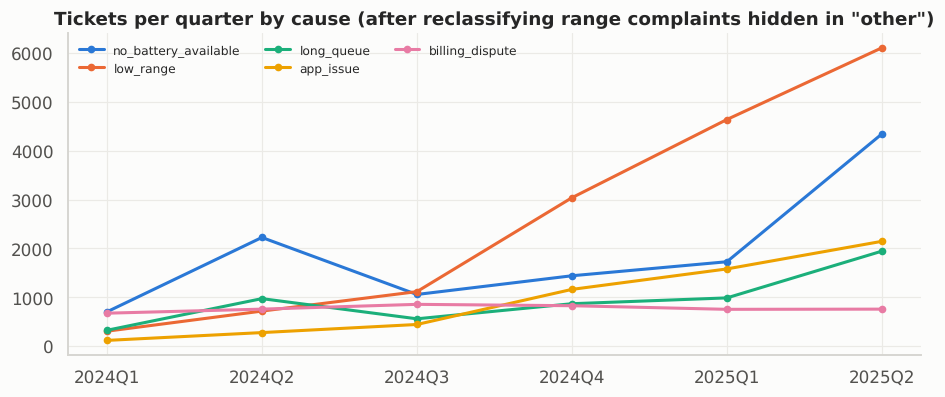

In [57]:
tk = tickets.copy()
tk['quarter'] = tk.created_ts.dt.to_period('Q').astype(str)
tk['cause'] = reclass.replace('low_range (reclassified)', 'low_range')
tq = pd.crosstab(tk.quarter, tk.cause)
tk['ticket_supplier'] = tk.battery_id.map(bat.supplier)
print('Share of range tickets (after text check) among tickets naming a battery, by supplier, vs supplier share of packs:')
print(pd.DataFrame({'range_ticket_share': tk.dropna(subset=['ticket_supplier']).groupby('ticket_supplier').cause.apply(lambda x: (x == 'low_range').mean()),
                    'share_of_packs': batteries.supplier.value_counts(normalize=True)}).round(3))
fig, ax = plt.subplots(figsize=(10, 3.8))
order = ['no_battery_available', 'low_range', 'long_queue', 'app_issue', 'billing_dispute', 'other']
for i, c in enumerate([c for c in order if c in tq.columns]):
    ax.plot(tq.index, tq[c], marker='o', ms=4, label=c, color=PAL[i])
ax.set_title('Tickets per quarter by cause (after reclassifying range complaints hidden in "other")'); ax.legend(frameon=False, fontsize=8, ncol=3)
save(fig, '14_tickets'); plt.show()

In [58]:
# CSAT: naive vs response-weighted (inverse probability by resolution bucket)
tk = tk[tk.resolution_status == 'resolved'].copy()
rr = tk.groupby('res_bucket', observed=True).csat_score.apply(lambda x: x.notna().mean())
tk['w'] = 1 / tk.res_bucket.map(rr).astype(float)
cs = tk.dropna(subset=['csat_score'])
naive = cs.groupby('cause').csat_score.mean()
weighted = cs.groupby('cause').apply(lambda d: np.average(d.csat_score, weights=d.w))
pd.DataFrame({'naive_csat': naive, 'weighted_csat': weighted, 'resolved_tickets': tk.groupby('cause').size(),
              'median_resolution_h': tk.groupby('cause').resolution_hours.median()}).round(2)

,naive_csat,weighted_csat,resolved_tickets,median_resolution_h
cause,,,,
app_issue,3.53,3.54,4924,13.0
billing_dispute,3.56,3.57,3999,13.3
long_queue,3.50,3.52,4892,13.1
low_range,3.55,3.55,13677,13.1
no_battery_available,3.60,3.61,9858,13.4


**D4 answer.** The text adds real information.
- **Every ticket filed as "other" is a battery/range complaint described in vehicle terms**: "general issue with the vehicle performance", "bike problem lag raha hai overall", "scooter weak lag raha hai aajkal". Reclassifying these 9,361 tickets lifts range complaints from 6,551 to 15,912, making **battery range the largest complaint cause** (ahead of 11,486 "no battery available"), and the fastest growing one.
- Riders who quote a number ("scooter dying at 52 km, bike problem?") report a median of 52 km, against the ~68 km a 2W pack delivered in H1 2024.
- Range tickets that name a battery are over-represented for Kyron packs (44% of their tickets vs 33-34% for Cellora and Amptek).
- About a third of billing disputes complain about a surcharge "laga diya bina bataye" (added without telling), but this share is the same in pilot and non-pilot cities and before the pilot, so these are not caused by the peak pilot.
- **CSAT** is ~3.5-3.6 for every cause and re-weighting for non-response changes it by less than 0.02, so CSAT carries little signal here; ticket volume and resolution time are more useful.

### D5. Anomalies worth flagging

In [59]:
anom = []
anom.append(('Firmware v3.2.0 timestamps', f'{bug.sum():,} events logged 5h30m early (10 Mar-14 Apr 2025); corrected in 3.2'))
anom.append(('Test stations', f'STN-TST-01/02 carried {len(test_ev):,} transactions across all hours; excluded'))
anom.append(('Kyron 2W lots KY-2407/08/09', 'Lose SOH ~3x faster per swap; all marked retired 15 Jun 2025'))
anom.append(('Retired packs still issued', f'{len(after):,} swaps issued a pack after its recorded retirement date'))
anom.append(('payment_mode', 'Always "partner_invoice", even for independent riders on STD/PEAK tariffs: a logging defect'))
anom.append(('Tickets outside data window', f'{int(out_of_range.sum())} tickets dated before 2024 or after Jun 2025; excluded'))
anom.append(('Decommissioned station', 'STN-DEL-051 (Wave 1, residential) closed 20 May 2025 after ~8 months'))
anom.append(('Near-duplicates', 'Documented offline-sync duplicates are essentially absent in this export'))
pd.DataFrame(anom, columns=['anomaly', 'detail'])

,anomaly,detail
0,Firmware v3.2.0 timestamps,"139,490 events logged 5h30m early (10 Mar-14 A..."
1,Test stations,"STN-TST-01/02 carried 62,031 transactions acro..."
2,Kyron 2W lots KY-2407/08/09,Lose SOH ~3x faster per swap; all marked retir...
3,Retired packs still issued,"36,109 swaps issued a pack after its recorded ..."
4,payment_mode,"Always ""partner_invoice"", even for independent..."
5,Tickets outside data window,85 tickets dated before 2024 or after Jun 2025...
6,Decommissioned station,"STN-DEL-051 (Wave 1, residential) closed 20 Ma..."
7,Near-duplicates,Documented offline-sync duplicates are essenti...


## 6. Key findings and recommendations

### What is really going on
1. **Growth hid three separate problems.** Swaps and revenue roughly tripled, but (a) failures spike to 10-12% every summer, (b) complaints per attempt nearly tripled, and (c) margin after battery wear fell back once a bad battery cohort arrived. The metrics move in different directions because they have different drivers.
2. **Service failures are a summer stock-out problem at Gen1 stations in hot cities.** Above ~40°C cabinet temperature, Gen1 chargers derate (charge time 88 → 140-190 minutes), racks empty, and "no charged battery" failures follow. The worst 30 stations are all Gen1 in Delhi NCR, Jaipur and Hyderabad and produce 42% of failures. 3W riders fail twice as often. Queue time itself is flat.
3. **Early failures are the primary driver of new-rider churn.** Two or more failed attempts in a rider's first two weeks more than doubles the odds of not returning (OR 2.2), and this explains most of the Gen1 and summer effect. Low battery health is a secondary, independent contributor; competitor promotions are not supported as a driver.
4. **One battery cohort is eroding range, complaints and margin.** Kyron 2W lots KY-2407/08/09 degrade 3x faster, deliver ~25% less range, account for an outsized share of range complaints (the largest and fastest-growing ticket cause once "other" is reclassified), and cost about ₹55 more in wear per swap than Cellora/Amptek packs. Retired Kyron packs were still being issued after their retirement date.
5. **The largest partner is not the most valuable.** ZipDrop's 28% amended discount and peak exemption make it the lowest-margin partner per swap; the amendment cost about ₹3.7M in eight months without changing its growth trend.
6. **Pricing works where the payer sees the price.** The base price rise caused no measurable volume loss. The peak pilot shifted 2.5-4.5 points of demand off-peak for independents and surcharge-billed partners, and nothing for exempt partners.

### Recommendations, in priority order
1. **Fix Gen1 before the next summer (highest impact on failures, complaints and churn).** Retrofit cooling or replace chargers at the 51 Gen1 stations, starting with the 30 worst in Delhi NCR, Jaipur and Hyderabad. Over two summers Gen1 stations produced about 45,000 more failed attempts than they would have at the Gen2/3 failure rate.
2. **Protect new riders' first two weeks.** Route new riders to Gen2/Gen3 stations, reserve charged packs for them at peak, and trigger a proactive credit or call after a second failed attempt. Track "2+ failures in first 14 days" as a leading churn KPI.
3. **Replace the Kyron 2W cohort and enforce retirement.** Block retired packs from being issued, recover cost from the supplier, add incoming-lot SOH testing, and spend the battery budget on replacement Cellora/Amptek packs and on 3W packs, not on more of the same.
4. **Renegotiate ZipDrop rather than sign an exclusive.** Move toward the 10-15% norm with volume tiers, remove the peak-surcharge exemption, and link any discount to off-peak usage.
5. **Extend peak pricing selectively.** Roll it out to the hot Gen1 cities once partner exemptions are removed; it is a demand-shaping lever, not a substitute for fixing chargers.
6. **Target future expansion at need.** Place new Gen3 capacity next to the Gen1 hot spots and 3W-heavy stations, not where sites are easiest to sign.
7. **Fix the data pipeline.** Correct the firmware time-zone bug, log real payment modes, enforce battery retirement flags, and auto-classify ticket text so "other" stops hiding the largest complaint.

In [60]:
print('Figures saved to ./figures:', sorted(os.listdir(FIG_DIR)))

Figures saved to ./figures: ['01_firmware_shift.png', '02_kpi_trends.png', '03_margin_bridge.png', '04_hour_season.png', '05_city_gen_month.png', '06_thermal_derating.png', '07_battery_range.png', '08_lots.png', '09_pilot.png', '10_partners.png', '11_cohort_churn.png', '12_churn_drivers.png', '13_expansion.png', '14_tickets.png']
